# **Integrated Live Analytics Platform: End-to-End Performance Mapping, NLP Sentiment, & AI Student Profiling Engine**

# **# 📊 SECTION 1: LIVE STRUCTURED OBSERVATION DATA**
### **This section represents the core baseline of our project. It contains the live manual observation data (Vocal, Linguistic, and Flow metrics) captured directly during the student evaluation sessions and converted into normalized weights.**

# **Technical Mapping Method:**
### **The raw behavioral metrics were recorded using a Bipolar Rating Scale ranging from -2 (Highly Negative) to +2 (Highly Positive), with 0 representing Neutral performance. These categorical weighting  scores were then systematically converted into normalized positive feature weights to enable unified algorithmic visualization.**

In [ ]:
# @title Structured live observation Data Frame:
import pandas as pd


df1 = pd.read_csv('/content/ vocal data (2).csv')
df2 = pd.read_csv('/content/ flow data (4).csv')
df3 = pd.read_csv('/content/ linguistic data (2).csv')

pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)


for df in [df1, df2, df3]:
    df['Participant Name'] = df['Participant Name'].astype(str).str.strip().str.title()

df1 = df1.add_prefix('Vocal_').rename(columns={'Vocal_Participant Name': 'Participant Name'})
df2 = df2.add_prefix('Flow_').rename(columns={'Flow_Participant Name': 'Participant Name'})
df3 = df3.add_prefix('Ling_').rename(columns={'Ling_Participant Name': 'Participant Name'})

df_final = df1.merge(df2, on='Participant Name', how='inner').merge(df3, on='Participant Name', how='inner')

df1.set_index('Participant Name', inplace=True)
df2.set_index('Participant Name', inplace=True)
df3.set_index('Participant Name', inplace=True)

df_final = pd.concat([df1, df2, df3], axis=1, join='outer')

df_final.fillna("Neutral", inplace=True)

df_final.reset_index(inplace=True)


print(f"Total Participants: {len(df_final)}")
print ("columns in final table:" , df_final.columns.tolist())
df_final.head(19)

Total Participants: 19
columns in final table: ['Participant Name', 'Vocal_session ID', 'Vocal_                                                                                                                                                                                                                                                                                                ,b,,b vdd', 'Vocal_Initail Tone ', 'Vocal_Tone Score', 'Vocal_Response Latency ', 'Vocal_Latency score', 'Vocal_Hesitation ', 'Vocal_hesitation score', 'Vocal_Energy shift', 'Vocal_Energy score', 'Vocal_Total Vocal value.', 'Vocal_Final lebel', 'Flow_session ID', 'Flow_Date', 'Flow_Participation role', 'Flow_Unnamed: 4', 'Flow_Social mirroring', 'Flow_Mirror Score', 'Flow_Engagement level', 'Flow_Engaegment Score', 'Flow_Mentor connection', 'Flow_Connection Score', 'Flow_Response Time', 'Flow_Response Score', 'Flow_Total flow value', 'Flow_Final lebal ', 'Ling_session ID', 'Ling_Date', 'Ling_vocab type', 'Ling

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal
0,Student 1,S-1,29/04/2026,confident,2,normal,0,minimal,2,same,0,4,Active Receptive,S_1,29/04/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_1,29/04/2026,active,2,complete,2,high,2,2.0,Articulate/Clear
1,Student 2,S-1,29/04/2026,Neutral,0,normal,0,mild,0,same,0,0,passive Reseptive,S_1,29/04/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Moderate,0,Moderate,0,0.0,Passive/Neutral,S_1,29/04/2026,passive,0,fragmented,-2,vague,-2,-1.3,Incoherent/Struggling
2,Student 3,S-2,02/05/2026,Anxious,-2,Normal,0,Heavy,-2,zigzag {unstable},-1,-5,Fragmented,S_2,02/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Moderate,0,Immediate,2,0.4,Passive/Neutral,S_2,02/05/2026,passive,0,fragmented,-2,vague,-2,-1.3,Incoherent/Struggling
3,Student 4,S-2,02/05/2026,Neutral,0,Normal,0,Heavy,-2,neutral stable,0,-2,Anxious,S_2,02/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Strong,2,Immediate,2,0.8,Steady Flow,S_2,02/05/2026,passive,0,complete,2,vague,2,1.3,Functional/Steady
4,Student 5,S-3,06/05/2026,confident,2,instant,2,mild,0,boost,2,6,Highly Engaged,S_3,06/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_3,06/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear
5,Student 6,S-3,19/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S_3,06/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_3,06/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear
6,Student 7,S-4,08/05/2026,Anxious,-2,delayed,-2,heavy,-2,same,0,-6,Fragmented,S_4,08/05/2026,Reluctant,-2,Flat,-2,Minimally engaged,-1,Weak,-2,Delayed,-2,-1.8,Low Flow / Struggling,S_4,08/05/2026,active,2,fragmented,-2,vague,-2,-0.7,Incoherent/Struggling
7,Student 8,S-4,08/05/2026,normal,0,Normal,0,mild,0,same,0,0,passive Reseptive,S_4,08/05/2026,Reluctant,-2,Flat,-2,Minimally engaged,-1,Weak,-2,Delayed,-2,-1.8,Low Flow / Struggling,S_4,08/05/2026,active,0,fragmented,-2,vague,-2,-1.3,Incoherent/Struggling
8,Student 9,S-5,09/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S_5,09/05/2026,Responsive,0,Strongly mirror,2,Moderately engaged,0,Strong,2,Moderate,0,0.8,Steady Flow,S_5,09/05/2026,active,2,complete,2,vague,2,2.0,Articulate/Clear
9,Student 10,S-5,09/05/2026,confident,2,instant,2,mild,0,boost,2,6,Active Receptive,S_5,09/05/2026,Expressive,2,Strongly mirror,2,Moderately engaged,0,Strong,2,Moderate,0,1.2,Steady Flow,S_5,09/05/2026,active,0,complete,2,high,2,1.3,Functional/Steady


# **# 🤖 SECTION 2: AUTOMATED TRANSCRIPT AI PROFILING SUMMARY**

## **This section performs automated inference strictly using the unstructured student transcript text data.**

# **Methodology & Prompting:**

###  The system utilizes custom **API Prompting engineered** to guide the **Groq LLM core**. By injecting structured prompt constraints, the **raw transcript data** is instantly parsed and mapped cleanly into individual capability profiles—detailing target **career tracks**, **educational goals**, and **actionable improvement plans without layout distortion.**

In [ ]:
# @title Indiviadual AI Profiling for FAI innovators Generated by using API model.

!pip -q install openai pandas
import pandas as pd, json, time, os, glob, html as h
from openai import OpenAI
from google.colab import userdata, output
from IPython.display import HTML, display
output.no_vertical_scroll()

# ---------- Setup ----------
KEY = userdata.get("GROQ_API_KEY").strip()
assert KEY.startswith("gsk_"), f"Ye Groq key nahi hai (shuru: {KEY[:4]})"
client = OpenAI(api_key=KEY, base_url="https://api.groq.com/openai/v1")
avail = [m.id for m in client.models.list().data]
MODEL = next(m for m in ["openai/gpt-oss-120b","llama-3.3-70b-versatile","llama-3.1-8b-instant","openai/gpt-oss-20b"] if m in avail)

# Search for the CSV file in both current folder and /content/
files = glob.glob("Chinar_Quantum*.csv") + glob.glob("/content/Chinar_Quantum*.csv")
assert files, "CSV Colab Files me nahi mili. Pehle upload karo."
CSV = max(files, key=os.path.getmtime)          # sabse nayi CSV
CACHE = "students_v3.json"
print("CSV:", CSV, "| Model:", MODEL)

# ---------- Grok/Groq se extraction ----------
PROMPT = """You prepare a professional learner profile for an organization's management.
Input: one learner's feedback row. Return ONLY JSON:
{"name": str, "education": short badge text or "",
 "org_feedback": 1-2 sentences on what the learner said about the organization/program,
 "goals": [learner's stated goals/aspirations],
 "status": [current job/study status, background, skills the learner stated about themselves],
 "org_value": [3-4 insights useful for the organization: strengths, commitment, engagement potential],
 "improvements": [2-4 areas where this learner needs development or support, based on gaps/challenges in the data]}
RULES:
- Professional third person ("The learner ..."), concise, no slang.
- name, education, org_feedback, goals, status, org_value: ONLY facts clearly stated about THIS learner.
- NEVER attribute to the learner anything said about mentors, staff or other people.
- Family, marital or personal details: include ONLY if the learner explicitly states them. If in doubt, omit.
- If nothing was said for a field, return empty list or "". Never invent facts. Each item under 22 words."""

def extract(row):
    text = "\n".join(f"{k}: {v}" for k, v in row.items() if pd.notna(v))
    for t in range(3):
        try:
            r = client.chat.completions.create(model=MODEL, temperature=0, response_format={"type":"json_object"},
                messages=[{"role":"system","content":PROMPT},{"role":"user","content":text}])
            return json.loads(r.choices[0].message.content)
        except Exception as ex:
            if t == 2: raise
            time.sleep(6)

def load_data(refresh=False):
    if os.path.exists(CACHE) and not refresh:
        return json.load(open(CACHE, encoding="utf-8"))
    df = pd.read_csv(CSV)
    df = df[df["Role"].astype(str).str.strip().str.lower() == "learner"]   # mentors skip
    data = []
    for i, row in df.iterrows():
        try: data.append(extract(row)); time.sleep(1.5)
        except Exception as ex: print(f"Row {i} failed: {ex}"); break
    json.dump(data, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)
    return data

# ---------- Card design ----------
BAD = ("married", "daughter", "family", "wife", "husband", "children")
PAL = [("#4f6fe8","#eef2ff"), ("#2fa37f","#ecfaf4"), ("#e5607e","#fff0f4"), ("#e0912b","#fff7e8"),
       ("#3b9ad9","#eef8ff"), ("#7d6be6","#f4f1ff"), ("#d9695f","#fff2f0"), ("#1fa5a5","#eafafa")]
SECTIONS = [("goals","🎯","Goals & Aspirations"), ("status","💼","Current Status & Background"),
            ("org_value","📊","Key Insights for Organization"), ("improvements","🛠️","Improvement Areas & Support Needed")]

def card(d, n):
    e = h.escape
    a, s = PAL[(n-1) % len(PAL)]
    name = d.get("name") or "Learner"
    edu = f"<span class='badge'>🎓 {e(d['education'])}</span>" if d.get("education") else ""
    org = (f"<div class='org'><div class='ol'>💬 ORGANIZATION FEEDBACK / ALIGNMENT</div><p>{e(d['org_feedback'])}</p></div>"
           if d.get("org_feedback") else "")
    secs = ""
    for key, ico, title in SECTIONS:
        items = [x for x in (d.get(key) or []) if not any(b in str(x).lower() for b in BAD)]
        if items:
            lis = "".join(f"<li>{e(str(i))}</li>" for i in items)
            secs += f"<div class='sec'><div class='st'><span>{ico}</span>{title}</div><ul>{lis}</ul></div>"
    return f"""<div class='card' style='--a:{a};--s:{s}'>
      <div class='head'><div class='av'>{e(name.strip()[:1].upper())}</div>
        <div class='nm'><h2>{e(name)}</h2>{edu}</div><div class='no'>#{n}</div></div>
      <div class='body'>{org}<div class='cols'>{secs}</div></div></div>"""

CSS = """<style>
.wrap{font-family:'Segoe UI',Roboto,sans-serif;background:#f4f6fb;padding:28px 22px;border-radius:16px;box-sizing:border-box;width:100%}
.title{text-align:center;font-size:34px;font-weight:800;color:#2b3a67;margin:0}
.sub{text-align:center;color:#5b6475;margin:6px 0 28px;font-size:17px;font-weight:600}
.list{width:100%;display:flex;flex-direction:column;gap:32px}
.card{background:#fff;border-radius:22px;overflow:hidden;box-shadow:0 8px 26px #2b3a6720;border:2px solid var(--s)}
.head{display:flex;align-items:center;gap:22px;padding:26px 34px;background:var(--a)}
.av{width:78px;height:78px;border-radius:50%;background:#fff;color:var(--a);font-size:38px;font-weight:800;display:flex;align-items:center;justify-content:center;flex:none}
.nm{flex:1}.nm h2{margin:0 0 10px;color:#fff;font-size:32px;font-weight:800}
.badge{display:inline-block;background:#ffffff33;color:#fff;border:1.5px solid #ffffffaa;padding:7px 18px;border-radius:30px;font-size:16px;font-weight:700}
.no{color:#ffffffcc;font-size:26px;font-weight:800}
.body{padding:26px 34px 32px;background:#fff}
.org{background:var(--s);border:2px solid var(--a);border-left:10px solid var(--a);border-radius:16px;padding:20px 26px;margin-bottom:22px}
.ol{font-size:16px;font-weight:800;letter-spacing:1px;color:var(--a);margin-bottom:8px}
.org p{margin:0;font-size:21px;line-height:1.55;font-weight:700;color:#1f2937}
.cols{display:grid;grid-template-columns:1fr 1fr;gap:20px}
.sec{background:var(--s);border-left:6px solid var(--a);border-radius:14px;padding:18px 24px}
.st{font-size:21px;font-weight:800;margin-bottom:10px;display:flex;align-items:center;gap:10px;color:var(--a)}
.st span{font-size:24px}
.sec ul{margin:0;padding-left:22px;font-size:18px;line-height:1.65;font-weight:600;color:#1f2937}
.sec li{margin:6px 0}
@media(max-width:850px){.cols{grid-template-columns:1fr}.head{padding:20px}.body{padding:20px}}
@media print{.card{break-inside:avoid;box-shadow:none}}
</style>"""

# ---------- Run ----------
def build_profiles(refresh=False, out="student_cards.html"):
    data = load_data(refresh)
    page = (f"{CSS}<div class='wrap'><div class='title'>Learner Profile Report</div>"
            f"<div class='sub'>{len(data)} learners • Chinar Quantum AI Learners</div>"
            f"<div class='list'>{''.join(card(d, i+1) for i, d in enumerate(data))}</div></div>")
    open(out, "w", encoding="utf-8").write(page)
    display(HTML(page)); print(f"✅ {len(data)} learner cards → {out}")

build_profiles()

<IPython.core.display.Javascript object>

CSV: Chinar_Quantum_AI_Learners_Feedback_Profile (3).csv | Model: openai/gpt-oss-120b


✅ 19 learner cards → student_cards.html


In [ ]:
# @title
import time
import random
import pandas as pd
from IPython.display import display, HTML
import os

# The CSV path is available as a global variable 'CSV' from cell 3Dwuk0wylWlL.
# Using globals().get() for robustness in case CSV is not strictly in local scope.
_csv_filename = globals().get('Chinar_Quantum_AI_Learners_Feedback_Profile (3).csv')
_csv_file_path = os.path.join('/content/Chinar_Quantum_AI_Learners_Feedback_Profile (3).csv')

# Add a check for file existence
if not os.path.exists(_csv_file_path):
    raise FileNotFoundError(f"The file '{_csv_file_path}' does not exist. Please ensure 'Chinar_Quantum_AI_Learners_Feedback_Profile (3).csv' is uploaded to your Colab environment.")

student_profiles_df = pd.read_csv(_csv_file_path)

def get_ai_feedback(row):
    # Retrieve column values safely using .get() with empty string as default.
    # Assuming 'Name' is the column name for the student's name based on KeyError.
    # Other column names are from the PROMPT in 3Dwuk0wylWlL.
    name_col = row.get('Name', '')
    edu_col = row.get('Education Background', '')
    goals_col = row.get('Future Plans / Goals', '')
    feedback_col = row.get('Feedback Summary (Core Points)', '')
    improvement_col = row.get('Key Area of Improvement', '')
    context_col = row.get('Current Business / Job Status', '')

    prompt = f"""
    You are a professional educational counselor. Generate a structured profile card for: {name_col}.

    Data:
    - Education: {edu_col}
    - Goals: {goals_col}
    - Feedback: {feedback_col}
    - Improvement: {improvement_col}
    - Context: {context_col}

    Instructions:
    1. Output strictly in valid HTML format.
    2. STRICTLY IGNORE any personal information (marriage, family, children).
    3. Use <h3> tags for titles with a font-size of 20px and bold weight.
    4. Provide the content in <p> tags with a font-size: 16px.
    5. CRITICAL: Do not include markdown tags like ```html or ``` in your response. Output raw HTML only.
    """

    # Ensure 'client' and 'MODEL' are accessible. Assuming they are global from previous cells.
    # Using globals().get() for robustness.
    _model_to_use = globals().get('MODEL', "llama-3.1-8b-instant")

    completion = client.chat.completions.create(
        model=_model_to_use,
        messages=[{"role": "user", "content": prompt}]
    )

    res = completion.choices[0].message.content
    res = res.replace("```html", "").replace("```", "")
    return res

# Initialize report_html as a proper HTML string to accumulate content
report_html = "<html><head><style>body { font-family: sans-serif; }</style></head><body>"

# Iterate over the correct student DataFrame (student_profiles_df)
for _, row in student_profiles_df.head(19).iterrows():
    colors = ['#e3f2fd', '#fce4ec', '#f1f8e9', '#fff3e0', '#f3e5f5']
    bg = random.choice(colors)

    name_for_print = row.get('Name', 'Unknown Participant')
    print(f"Generating profile for: {name_for_print}...")
    try:
        content = get_ai_feedback(row)

        report_html += f"""
        <div style="background-color: {bg}; padding: 30px; border-radius: 15px; margin: 20px auto; width: 80%; box-shadow: 0 4px 8px rgba(0,0,0,0.1);">
            <h1 style="font-size: 32px; color: #333; border-bottom: 2px solid #555; padding-bottom: 10px;">{name_for_print}</h1>
            {content}
        </div>
        """
        time.sleep(3)
    except Exception as e:
        print(f"Error processing {name_for_print}: {e}")

report_html += "</body></html>"

display(HTML(report_html))

Generating profile for: Student 1...
Generating profile for: Student 2...
Generating profile for: Student 3...
Generating profile for: Student 4...
Generating profile for: Student 5...
Generating profile for: Student 6...
Generating profile for: Student 7...
Generating profile for: Student 8...
Generating profile for: Student 9...
Generating profile for: Student 10...
Generating profile for: Student 11...
Generating profile for: Student 12...
Generating profile for: Student 13...
Generating profile for: Student 14...
Generating profile for: Student 15...
Generating profile for: Student 16...
Generating profile for: Student 17...
Generating profile for: Student 18...
Generating profile for: Student 19...


## **## 📊 Section 3: Multi-Dimensional Performance Classification Engine – Transforming Live Tri-Field Data (Vocal, Linguistic, Flow) & Sentiment Metrics into Participant Benchmarks via Conditional Logic Gap Analysis**.

In [ ]:
import numpy as np

Weighting_logic_map = {
    'confident': 2, 'Neutral': 0, 'Anxious': -2,
    'boost': 2, 'same': 0, 'zigzag': -2,'neutral stable':0,
    'instant': 2, 'normal': 0, 'delayed': -2,
    'Immediate': 2, 'Moderate': 0, 'Delayed':-2 ,
    'fully engaged': 2, 'moderately engaged': 0,'Minimally engaged':-1,
    'Strong':2,'Moderate':0,'Weak':-2,
    'Strongly mirror': 2, 'Partially mirror':0, 'Flat': -2,
    'Expressive':2,'Responsive':0,'Reluctant':-2,
    'high': 2, 'vague':-2 , 'complete': 2, 'Fragmented': -2,
    'active': 2, 'pasive': 0,'minimal':2,'mild':0,'Heavy':-2,
}

def run_analytics(row):
    # Corrected column name for 'Vocal_Total Vocal value.'
    v = row.get('Vocal_Total sentiment Vocal Weights.', 0)
    f = row.get('Flow_Total flow value', 0)
    l = row.get('Ling_total ling value', 0)


    if v >= 2 and f >= 2  and l >= 2:
        return "Star Performance : Exceptional Potential"

    elif l >= 1 and v <= -2:
        return "Hesitant Expert : Knowledgeable but Needs Confidence"

    elif v >= 2 and f >= 1 and l >= -1:
        return "Enthusiastic Learner : High Engagement but Needs Clarity"

    elif (-2 <= v <= 2 ) and (-2 <= f <= 2) and (-2 <= l <= 2):
        return "Balanced Profile : Stable Baseline"

    elif v <= -5 or f <= -1.8 or l <= -1.3:
        return "Knowledge Gap : Targeted Training Required"

    elif  v >= -1 and f >= 0.2 and l >= 0.2:
        return "Cognitive Agile : precise thinker"

    else:
      return "Steady Contributor : Developing Profile"

df_final['Performance_Tag'] = df_final.apply(run_analytics, axis=1)


print("PARTICIPANT LIST AND PERFORMANCE LABELS")
print("")

count = 1

df_final_clean = df_final.reset_index()


for index, row in df_final_clean.iterrows():

    name = row['Participant Name']
    tag = row['Performance_Tag']

    print(count, ".", name)
    print("Result Tag:", tag)
    print("-" * 30)

    count = count + 1

print("Total Participants:", len(df_final_clean))

PARTICIPANT LIST AND PERFORMANCE LABELS

1 . Student 1
Result Tag: Balanced Profile : Stable Baseline
------------------------------
2 . Student 2
Result Tag: Balanced Profile : Stable Baseline
------------------------------
3 . Student 3
Result Tag: Balanced Profile : Stable Baseline
------------------------------
4 . Student 4
Result Tag: Balanced Profile : Stable Baseline
------------------------------
5 . Student 5
Result Tag: Balanced Profile : Stable Baseline
------------------------------
6 . Student 6
Result Tag: Balanced Profile : Stable Baseline
------------------------------
7 . Student 7
Result Tag: Balanced Profile : Stable Baseline
------------------------------
8 . Student 8
Result Tag: Balanced Profile : Stable Baseline
------------------------------
9 . Student 9
Result Tag: Balanced Profile : Stable Baseline
------------------------------
10 . Student 10
Result Tag: Balanced Profile : Stable Baseline
------------------------------
11 . Student 11
Result Tag: Balanced 

In [ ]:
# @title participants profile insights:

def generate_simple_report(row):
    label = row['Performance_Tag']

    if label == "Star Performance":
        insight = "Excellent performance! The student is at a 'Peak Level' in communication and logic. They have high potential for advanced programs."
        pathway = "Advanced Track: Highly suitable for high-level Data Research and AI modules."

    elif label == "Cognitive Agile: Precise Thinker":
        insight = "Sharp and precise mind. The student understands logic perfectly but is currently a bit quiet or hesitant to speak."
        pathway = "Technical Track: Recommended for Backend Development and Mathematical Logic where accuracy is key."

    elif label == "Enthusiastic Learner":
        insight = "Very active and full of energy. However, their technical language and programming foundation currently need more work."
        pathway = "Foundational Track: Needs to focus on Basic Python and Logic Building to strengthen their technical roots."

    elif label == "Hesitant Expert":
        insight = "A 'Silent Expert' who knows the answers but lacks confidence to speak up. Their knowledge is strong but they hesitate in groups."
        pathway = "Interactive Track: Should join group discussions to help them share their expertise more confidently."

    elif label == "Knowledge Gap":
        insight = "The student is currently struggling with core concepts. They need extra support to understand basic technical language."
        pathway = "Remedial Track: Recommended to start again with basic Math and Elementary Coding classes."

    else:
        insight = "Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential."
        pathway = "Standard Track: Perfectly suitable for standard Data Analytics and Python programs."

    return pd.Series([insight, pathway])

df_final_clean[['Final_Insight', 'Final_Roadmap']] = df_final_clean.apply(generate_simple_report, axis=1)
import pandas as pd
pd.set_option('display.max_rows', None)
print("="*90)
print("CHINAR QUANTUM AI: Individual Deep Analysis Report ASSESSMENT")
print("="*80)
for index, row in df_final_clean.iterrows():

  print(f"\n▶ ANALYSIS FOR: {row['Participant Name'].upper()}")
  print(f"{'─' * 45}")

  print(f"PROFILE STATUS : {row['Performance_Tag']}")

  print(f"\nDEEP ANALYSIS REPORT:")

  print(row['Final_Insight'])

  print(f"\nACADEMIC RECOMMENDATION & PATHWAY:")

  print(row['Final_Roadmap'])

  print(f"\n" + "="*90)
  print(f"\n[DONE: {len(df_final_clean)} Participants Processed Successfully]")

CHINAR QUANTUM AI: Individual Deep Analysis Report ASSESSMENT

▶ ANALYSIS FOR: STUDENT 1
─────────────────────────────────────────────
PROFILE STATUS : Balanced Profile : Stable Baseline

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


[DONE: 19 Participants Processed Successfully]

▶ ANALYSIS FOR: STUDENT 2
─────────────────────────────────────────────
PROFILE STATUS : Balanced Profile : Stable Baseline

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


[DONE: 19 Participants Processed Successfully]

▶ ANALYSIS FOR: STUDENT 3
─────────────────────────────────────

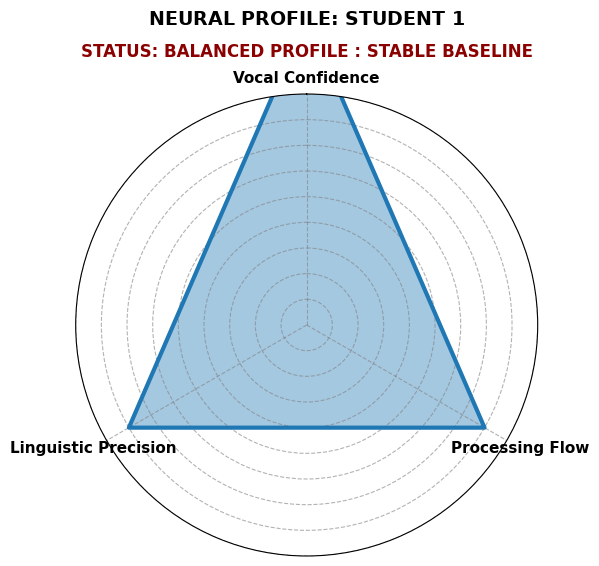

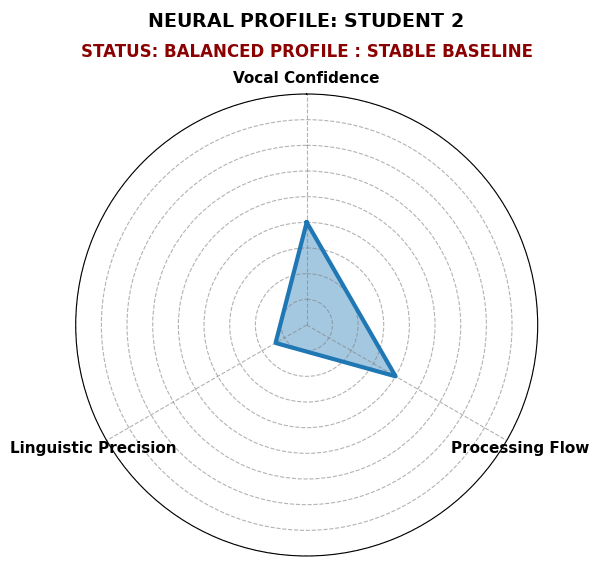

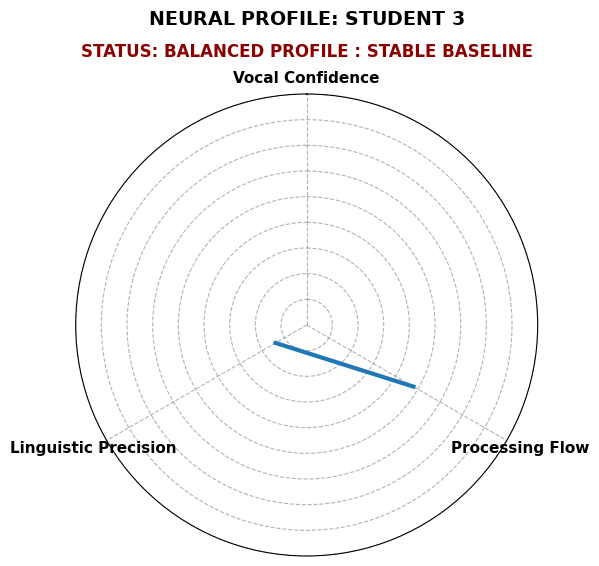

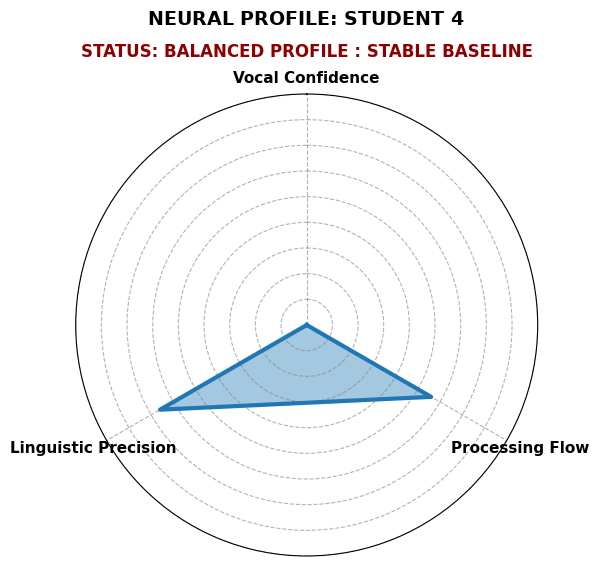

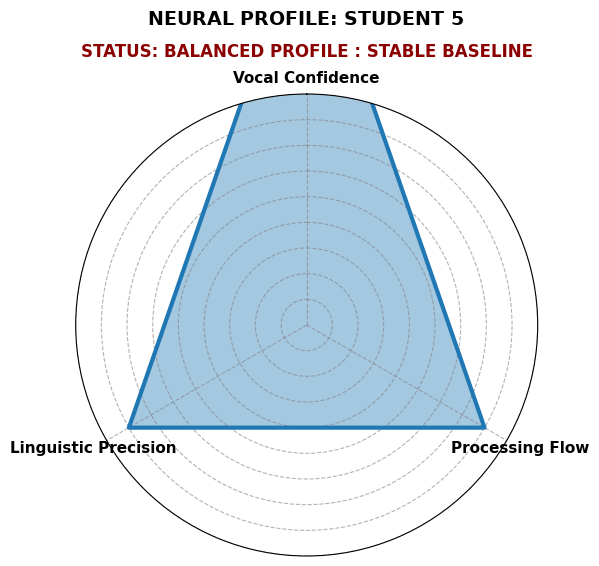

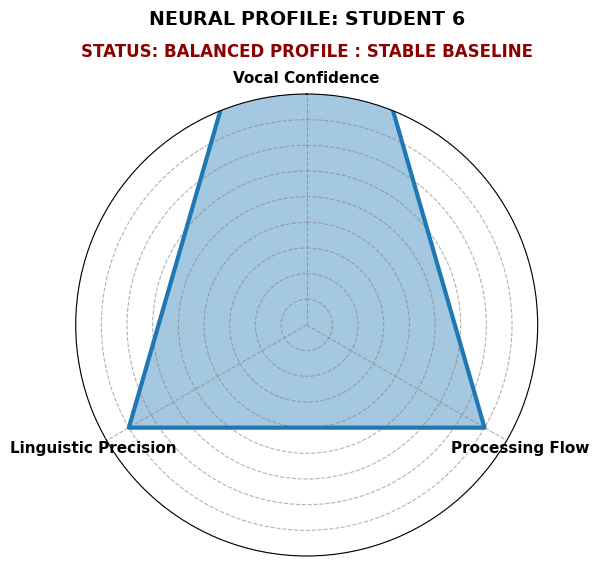

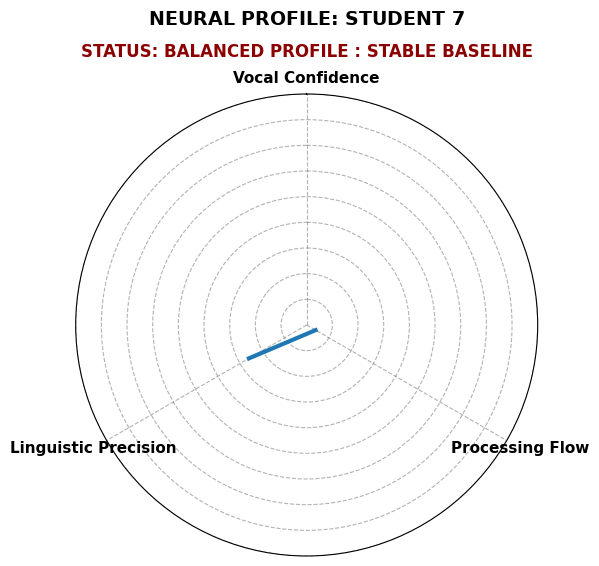

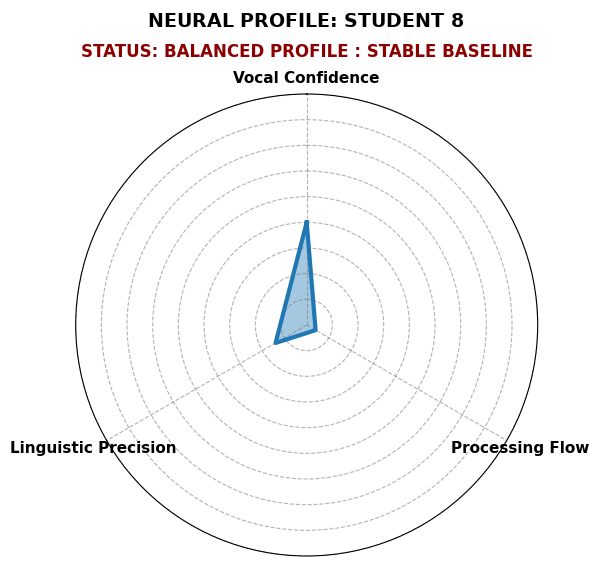

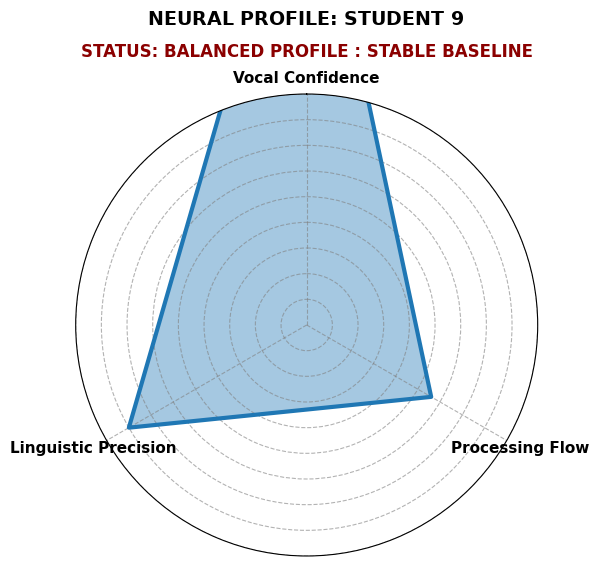

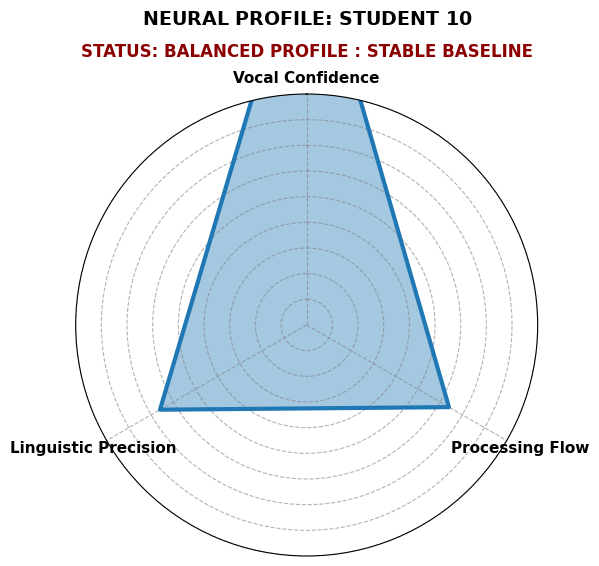

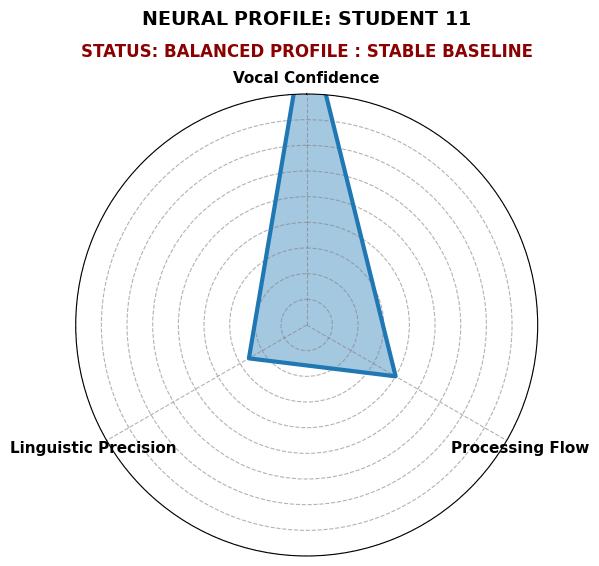

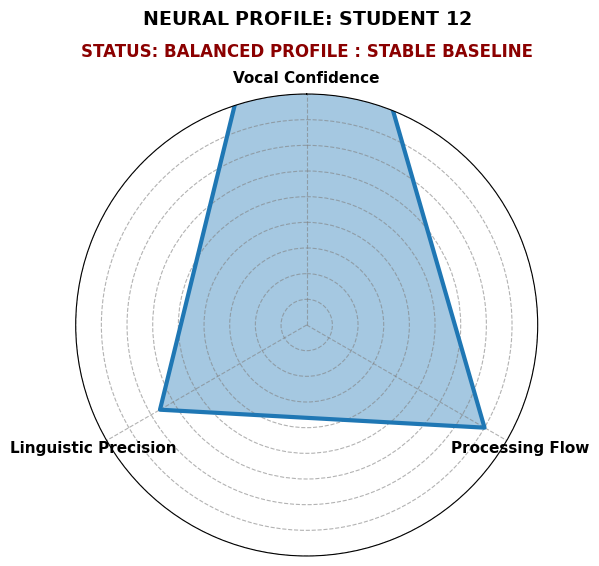

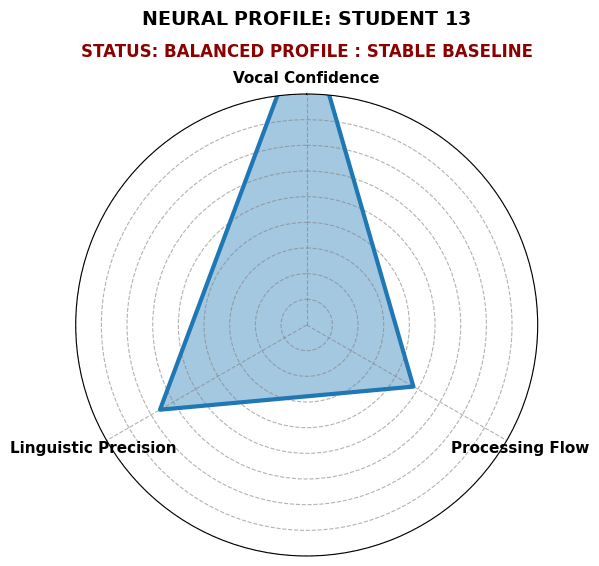

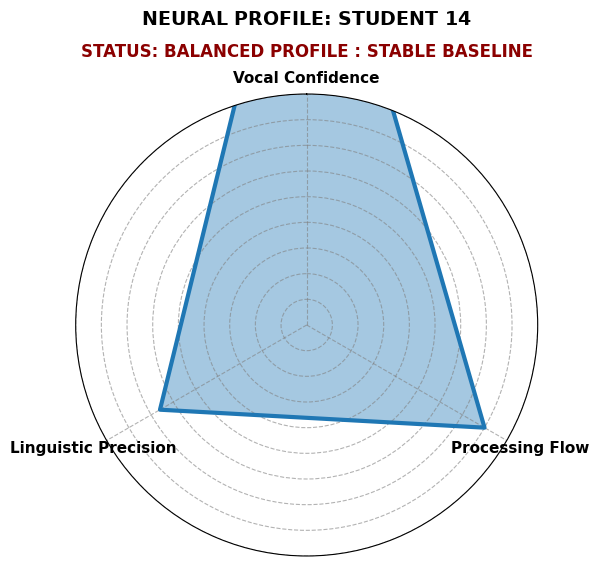

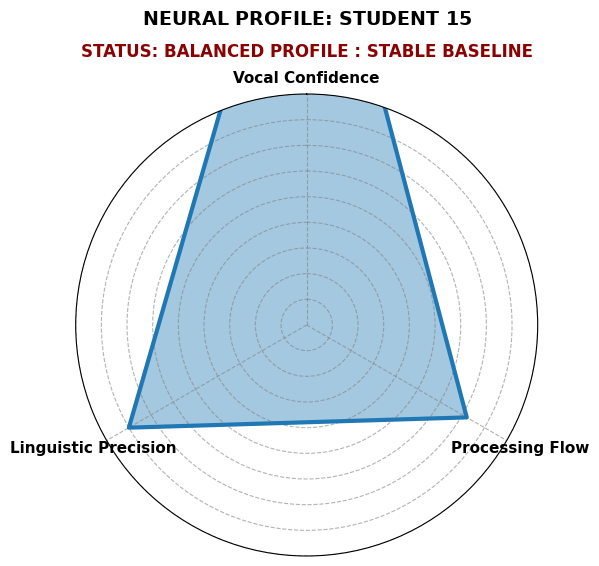

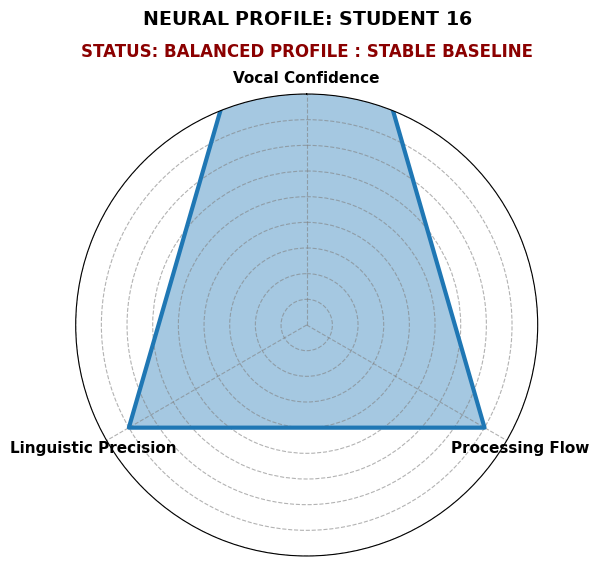

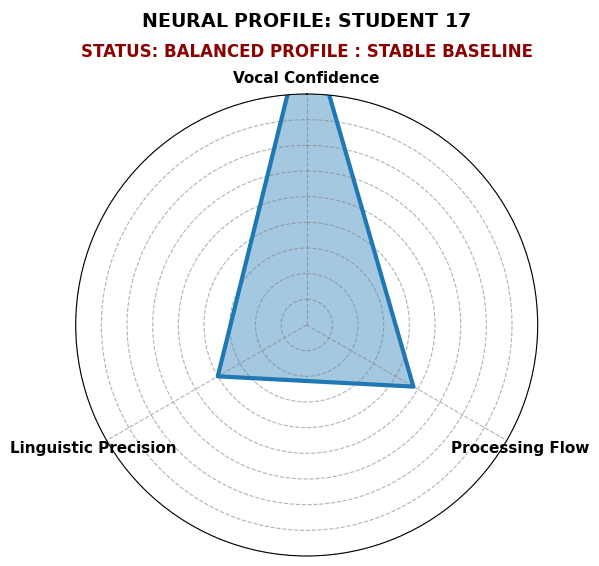

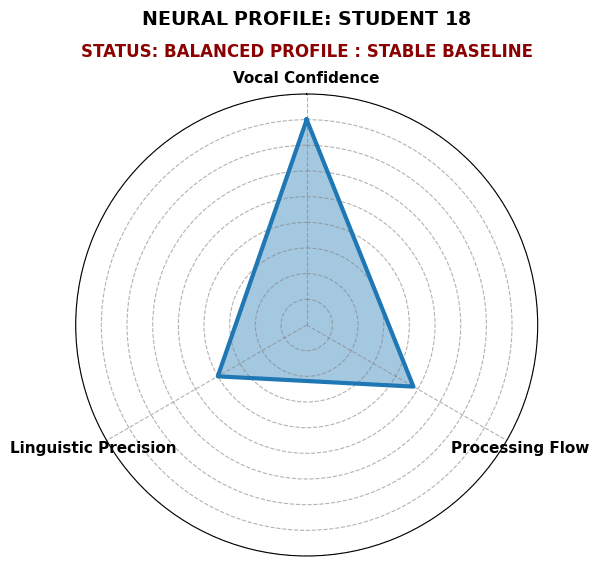

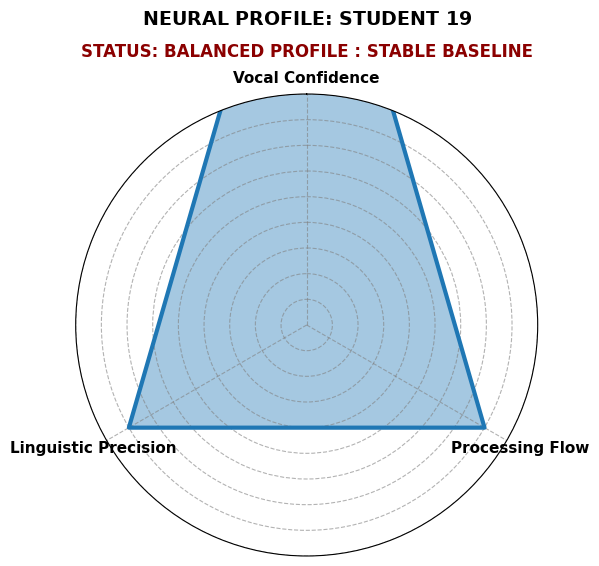

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def draw_neural_map(row):

    categories = ['Vocal Confidence', 'Processing Flow', 'Linguistic Precision']
    values = [row['Vocal_Total Vocal value.']+2, row['Flow_Total flow value']+2, row['Ling_total ling value']+2]


    angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()


    values_plot = values + [values[0]]
    angles_plot = angles + [angles[0]]

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))


    ax.fill(angles_plot, values_plot, color='#1f77b4', alpha=0.4)
    ax.plot(angles_plot, values_plot, color='#1f77b4', linewidth=3)


    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)


    for i, angle in enumerate(angles):

        alignment = 'center'
        ax.text(angle, 4.8, categories[i], size=11, weight='bold',
                ha=alignment, va='center', rotation=0)


    ax.set_xticks(angles)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_ylim(0, 4.5)
    ax.grid(True, color='grey', linestyle='--', alpha=0.6)

    plt.text(0.5, 1.15, f"NEURAL PROFILE: {row['Participant Name'].upper()}",
             transform=ax.transAxes, size=14, weight='bold', ha='center')

    plt.text(0.5, 1.08, f"STATUS: {row['Performance_Tag'].upper()}",
             transform=ax.transAxes, size=12, weight='bold', ha='center', color='darkred')


for index, row in df_final_clean.iterrows():
    draw_neural_map(row)

# **## 📝 Section 4: Unstructured Text Analytics: Extracting Sentiment Insights via VADER Lexicon NLP Model**.

In [ ]:
# @title Default title text
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt

sia = SentimentIntensityAnalyzer()

def analyze_student(name, session, text, high_conf, low_conf):
    hesitation = ["uh", "umm", "actually", "like", "sorry", "for example"]

    t = text.lower()
    high_count = sum(1 for w in high_conf if w in t)
    low_count  = sum(1 for w in low_conf  if w in t)
    total = high_count + low_count
    confidence_score = round((high_count/total)*10,1) if total>0 else 5.0

    hes_count = sum(t.count(w) for w in hesitation)
    cognitive_load = "High" if hes_count>5 else "Moderate" if hes_count>2 else "Low"

    sentiment = sia.polarity_scores(text)
    overall   = "Positive" if sentiment['compound']>=0.05 else \
                "Negative" if sentiment['compound']<=-0.05 else "Neutral"

    print("="*42)
    print(f"  {name.upper()} — INTERACTION ANALYSIS")
    print(f"  Session : {session}")
    print(f"  Analyst : Iram")
    print("="*42)
    print(f"  Confidence Score : {confidence_score}/10")
    print(f"  Cognitive Load   : {cognitive_load} ({hes_count} hesitation words)")
    print(f"  Sentiment        : {overall} ({round(sentiment['compound'],2)})")
    print(f"  Positive Language: {round(sentiment['pos']*100)}%")
    print(f"  Negative Language: {round(sentiment['neg']*100)}%")
    print("="*42)

    fig, axes = plt.subplots(1, 3, figsize=(13,4))
    fig.suptitle(f"{name} — Interaction Analysis", fontsize=13, fontweight='bold')
    axes[0].bar(["High","Low"],[high_count,low_count],color=["#2ecc71","#e74c3c"],width=0.4)
    axes[0].set_title(f"Confidence\n{confidence_score}/10")
    axes[0].set_ylabel("Word Count")
    axes[1].bar(["Hesitation Words"],[hes_count],color=["#e67e22"],width=0.4)
    axes[1].set_title(f"Cognitive Load\n{cognitive_load}")
    axes[1].set_ylabel("Count")
    axes[2].bar(["Positive","Negative","Neutral"],
                [sentiment['pos'],sentiment['neg'],sentiment['neu']],
                color=["#2ecc71","#e74c3c","#3498db"],width=0.4)
    axes[2].set_title(f"Sentiment\n{overall}")
    axes[2].set_ylabel("Score")
    plt.tight_layout()
    plt.show()

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


# **Comprehensive Participant Profiles: 360 Degree Data Alignment & Individual Performance Tracking.**

# **Overview:**

# In this section, we combine all data layers for each individual participant into a single, unified view. Scroll down to see the end-to-end performance tracking—from live observations to text sentiment—for every team member.

# **Each profile follows this alignment structure:**


# **Live Observation & Tri-Field Data (Vocal, Linguistic, Flow)**

# **Structured Insights & Neuro-Map Visualization**

# **Unstructured Text Analysis (VADER NLP Sentiment Scores)**

# **Automated AI Profiling via API Integration for Each Student.**

In [ ]:
#@title 📊 Live Observation Metrics for Student 1.
df_final.iloc[0:1]
df_final.iloc[[0]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
0,Student 1,S-1,29/04/2026,confident,2,normal,0,minimal,2,same,0,4,Active Receptive,S_1,29/04/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_1,29/04/2026,active,2,complete,2,high,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


In [ ]:
#@title 📉 Structured Analytical Gaps & Neuro Map  for Student 1.

```
▶ ANALYSIS FOR: STUDENT 1
─────────────────────────────────────────────
PROFILE STATUS : Star Performance : Exceptional Potential

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.

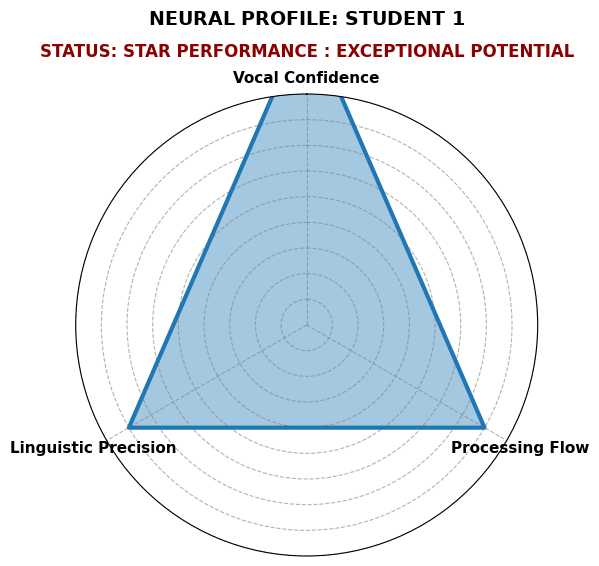

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


  STUDENT 1 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 1
  Analyst : Iram
  Confidence Score : 7.8/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.98)
  Positive Language: 22%
  Negative Language: 2%


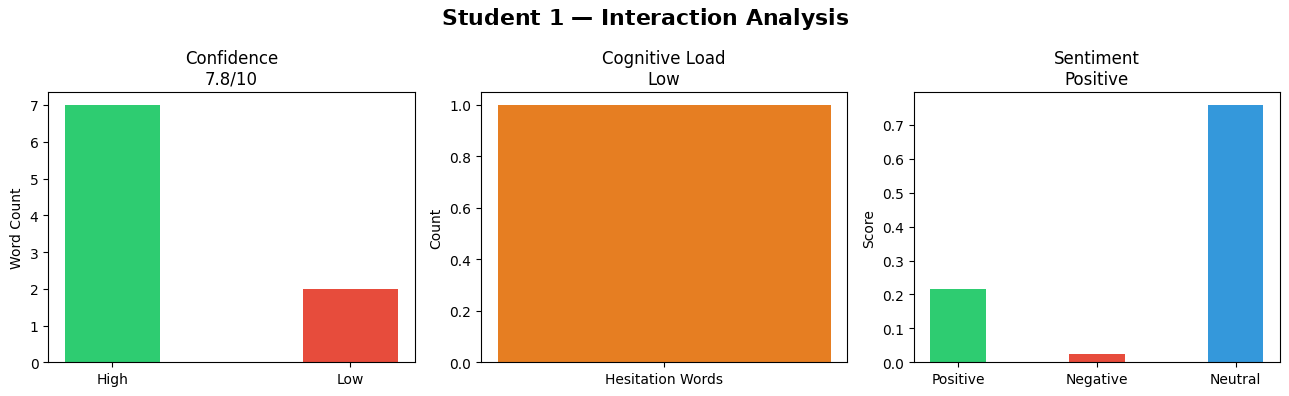

In [ ]:
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt

sia = SentimentIntensityAnalyzer()

def analyze_student(name, session, text, high_conf, low_conf):
    hesitation = ["uh", "umm", "actually", "like", "sorry", "for example"]

    t = text.lower()
    high_count = sum(1 for w in high_conf if w in t)
    low_count  = sum(1 for w in low_conf  if w in t)
    total = high_count + low_count
    confidence_score = round((high_count/total)*10,1) if total>0 else 5.0

    hes_count = sum(t.count(w) for w in hesitation)
    cognitive_load = "High" if hes_count>5 else "Moderate" if hes_count>2 else "Low"

    sentiment = sia.polarity_scores(text)
    overall   = "Positive" if sentiment['compound']>=0.05 else \
                "Negative" if sentiment['compound']<=-0.05 else "Neutral"

    print("="*42)
    print(f"  {name.upper()} — INTERACTION ANALYSIS")
    print(f"  Session : {session}")
    print(f"  Analyst : Iram")
    print("="*42)
    print(f"  Confidence Score : {confidence_score}/10")
    print(f"  Cognitive Load   : {cognitive_load} ({hes_count} hesitation words)")
    print(f"  Sentiment        : {overall} ({round(sentiment['compound'],2)})")
    print(f"  Positive Language: {round(sentiment['pos']*100)}%")
    print(f"  Negative Language: {round(sentiment['neg']*100)}%")
    print("="*42)

    fig, axes = plt.subplots(1, 3, figsize=(13,4))
    fig.suptitle(f"{name} — Interaction Analysis", fontsize=13, fontweight='bold')
    axes[0].bar(["High","Low"],[high_count,low_count],color=["#2ecc71","#e74c3c"],width=0.4)
    axes[0].set_title(f"Confidence\n{confidence_score}/10")
    axes[0].set_ylabel("Word Count")
    axes[1].bar(["Hesitation Words"],[hes_count],color=["#e67e22"],width=0.4)
    axes[1].set_title(f"Cognitive Load\n{cognitive_load}")
    axes[1].set_ylabel("Count")
    axes[2].bar(["Positive","Negative","Neutral"],
                [sentiment['pos'],sentiment['neg'],sentiment['neu']],
                color=["#2ecc71","#e74c3c","#3498db"],width=0.4)
    axes[2].set_title(f"Sentiment\n{overall}")
    axes[2].set_ylabel("Score")
    plt.tight_layout()
    plt.show()

 #@title 🧠 Behavioral Insights from Unstructured Data for  Student 1
analyze_student(
    name    = "Student 1",
    session = "FAI Mentorship Session 1",
    high_conf = ["definitely", "will", "exploring", "sustainable",
                 "future", "financial stability", "i wanted"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "circumstances", "not sure"],
    text    = """
Sorry ma'am. Yes ma'am. Alhamdulillah. basically business is not up to my expectation
because of some circumstances GST and there's no certainty in business right now.
I wanted something different something sustainable AI is the future that's why I'm here exploring things.
I'm just trying to survive. My parents are retired. My father used to work in JK bank
and my mother was government teacher.
I am using chat GPT and other tools to brush up on mathematics and programming.
Reason is financial stability. So it's easy to cope up with things.
Yes sir I will definitely explore it. Yes sir yes sir yes sir.
I don't have a laptop as such. BCOM 2015 pass out technical business investments.
Thank you sir. Thank you very much. Very nice talking to you sir.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 1..
from IPython.display import display, HTML
import re


student1_pattern = r'(<div.*?<h1.*?Student 1.*?</h1>.*?</div>)'
match = re.search(student1_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student1_section_html = match.group(1)
    display(HTML(student1_section_html))
else:
    display(HTML("<p>Student 1's profile not found.</p>"))

In [ ]:
#@title 📊 Live Observation Metrics for Student 2
df_final.iloc[0:1]
df_final.iloc[[1]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
1,Student 2,S-1,29/04/2026,Neutral,0,normal,0,mild,0,same,0,0,passive Reseptive,S_1,29/04/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Moderate,0,Moderate,0,0.0,Passive/Neutral,S_1,29/04/2026,passive,0,fragmented,-2,vague,-2,-1.3,Incoherent/Struggling,Balanced Profile : Stable Baseline


In [ ]:
#@title 📉 Structured Analytical Gaps & Neuro Map for Student 2


```
▶ ANALYSIS FOR: STUDENT 2
─────────────────────────────────────────────
PROFILE STATUS : Balanced Profile : Stable Baseline

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


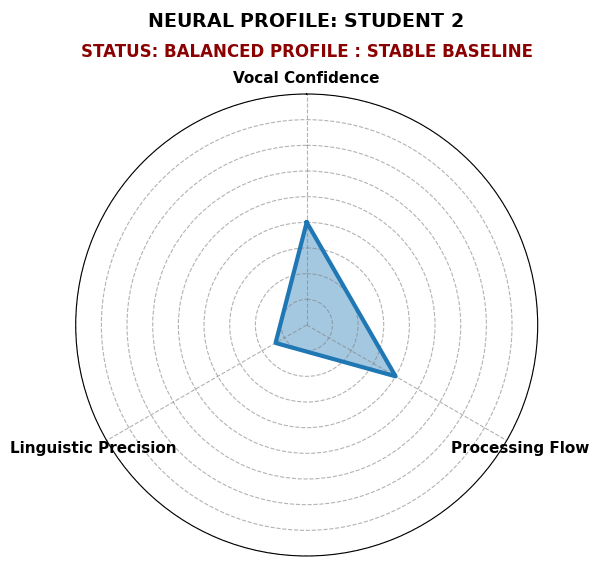

  STUDENT 2 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 1
  Analyst : Iram
  Confidence Score : 6.2/10
  Cognitive Load   : High (6 hesitation words)
  Sentiment        : Positive (0.97)
  Positive Language: 23%
  Negative Language: 0%


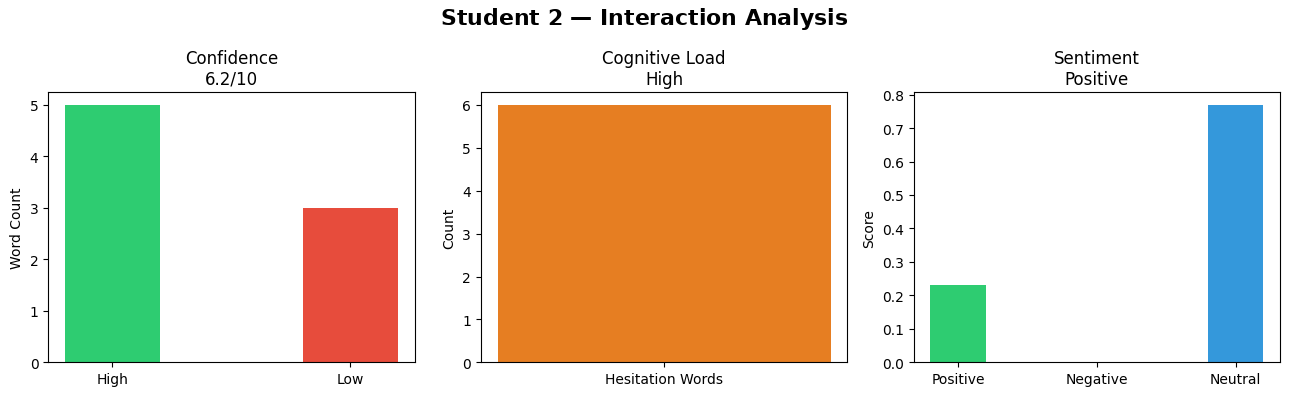

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 2.

analyze_student(
    name     = "Student 2",
    session  = "FAI Mentorship Session 1",
    high_conf = ["definitely", "agree", "possible", "yes",
                 "machine learning", "21st century", "innovation"],
    low_conf  = ["maybe", "uh", "umm", "actually", "like", "for example"],
    text     = """
Yes sir. Alhamdulillah. Science background non-med.
Actually school, instructions already. School structure techniques.
21st century skills, meaning students.
Yes sir. Agree. There is a huge gap between what we are doing and where world is going.
Electronics, gate circuits, street lights, next level.
Machine learning instruction, machine language. Yes sir.
Actually students, for example, descriptive exam, AI role, scope of AI.
Sir project. Yes sir. Project like example machine learning.
Yes sir robotic label. Possible sir. Possible.
For example class, machine learning actually sir suggestion sir.
Good day sir.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 2.
from IPython.display import display, HTML
import re

student2_Mr_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Mr\. Student 2\s*</h1>.*?</div>)'

print(f"DEBUG: Pattern being used: {student2_Mr_pattern}")

print(f"DEBUG: First 500 chars of report_html: {report_html[:500]}")

match = re.search(student2_Mr_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student2_mr_section_html = match.group(1)
    print(f"DEBUG: Matched section starts with: {student2_mr_section_html[:200]}")
    display(HTML(student2_mr_section_html))
else:
    display(HTML("<p>Student 2's profile not found.</p>"))

DEBUG: Pattern being used: (<div[^>]*>\s*<h1[^>]*>\s*Mr\. Student 2\s*</h1>.*?</div>)
DEBUG: First 500 chars of report_html: <html><head><style>body { font-family: sans-serif; }</style></head><body>
        <div style="background-color: #f3e5f5; padding: 30px; border-radius: 15px; margin: 20px auto; width: 80%; box-shadow: 0 4px 8px rgba(0,0,0,0.1);">
            <h1 style="font-size: 32px; color: #333; border-bottom: 2px solid #555; padding-bottom: 10px;">Student 1</h1>
            <div class="profile-card" style="border:1px solid #ccc; padding:20px; max-width:400px; font-family:Arial, Helvetica, sans-serif;">
    
DEBUG: Matched section starts with: <div style="background-color: #fce4ec; padding: 30px; border-radius: 15px; margin: 20px auto; width: 80%; box-shadow: 0 4px 8px rgba(0,0,0,0.1);">
            <h1 style="font-size: 32px; color: #333; 


In [ ]:
#@title 📊 Live Observation Metrics for Student 3.
df_final.iloc[0:1]
df_final.iloc[[2]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
2,Student 3,S-2,02/05/2026,Anxious,-2,Normal,0,Heavy,-2,zigzag {unstable},-1,-5,Fragmented,S_2,02/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Moderate,0,Immediate,2,0.4,Passive/Neutral,S_2,02/05/2026,passive,0,fragmented,-2,vague,-2,-1.3,Incoherent/Struggling,Balanced Profile : Stable Baseline


In [ ]:
#@title 📉 Structured Analytical Gaps & Neuro Map for Student 3.

```
▶ ANALYSIS FOR: STUDENT 3
─────────────────────────────────────────────
PROFILE STATUS : Knowledge Gap : Targeted Training Required

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


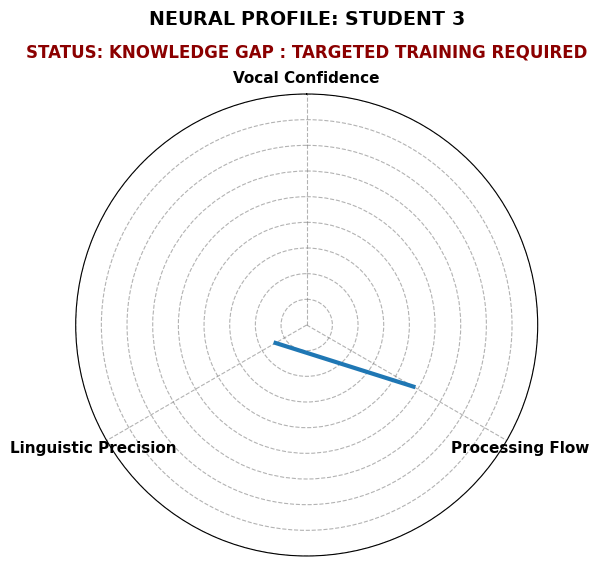

  STUDENT 3 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 2
  Analyst : Iram
  Confidence Score : 7.5/10
  Cognitive Load   : Low (0 hesitation words)
  Sentiment        : Positive (0.97)
  Positive Language: 50%
  Negative Language: 12%


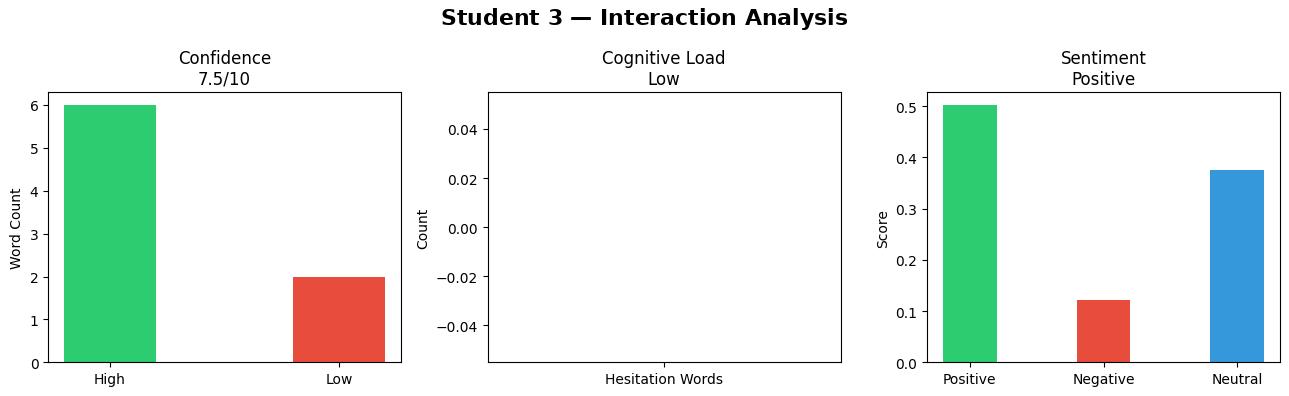

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 3.
analyze_student(
    name     = "Student 3",
    session  = "FAI Mentorship Session 2",
    high_conf = ["contribute", "data science", "python",
                 "hard work", "yes", "good"],
    low_conf  = ["shy", "maybe", "uh", "umm", "not sure", "difficult"],
    text     = """
Yes ma'am. All good. Thank you.
Ma'am shy person. Yes ma'am. Hard work.
I am not tired. Yes ma'am. Data science.
Python. Yes. Yes ma'am.
Difficult. Yes ma'am I want to contribute.
Yes ma'am. No ma'am thank you so much.
It's all right. Good.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 3.
from IPython.display import display, HTML
import re

# Searching for the specific section of Student 3 in the report_html
student3_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 3 \(Student 3\)\s*</h1>.*?</div>)'
match = re.search(student3_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student3_html = match.group(1)
    display(HTML(student3_html))
else:
    print("Student 3's profiling section was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 4	.
df_final.iloc[0:1]
df_final.iloc[[3]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
3,Student 4,S-2,02/05/2026,Neutral,0,Normal,0,Heavy,-2,neutral stable,0,-2,Anxious,S_2,02/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Strong,2,Immediate,2,0.8,Steady Flow,S_2,02/05/2026,passive,0,complete,2,vague,2,1.3,Functional/Steady,Balanced Profile : Stable Baseline


In [ ]:
#@title 📉 Structured Analytical Gaps & Neuro Map for STUDENT 4.

```
▶ ANALYSIS FOR: STUDENT 4
─────────────────────────────────────────────
PROFILE STATUS : Hesitant Expert : Knowledgeable but Needs Confidence

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


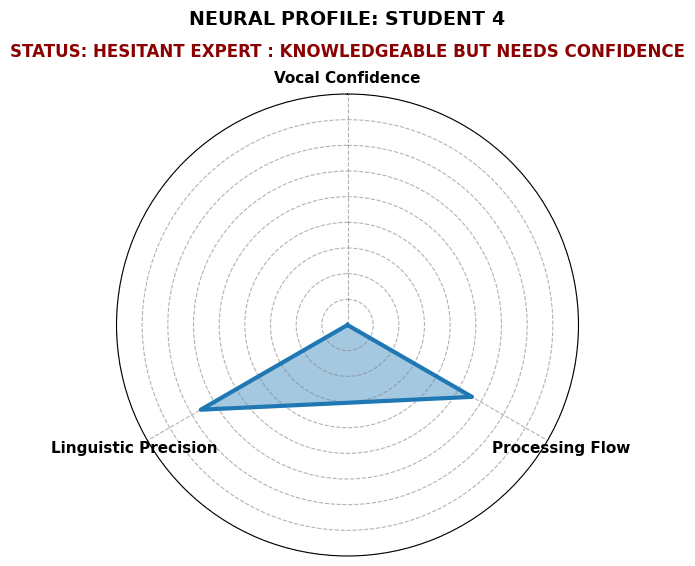

  STUDENT 4 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 2
  Analyst : Iram
  Confidence Score : 7.0/10
  Cognitive Load   : Low (0 hesitation words)
  Sentiment        : Positive (0.98)
  Positive Language: 46%
  Negative Language: 10%


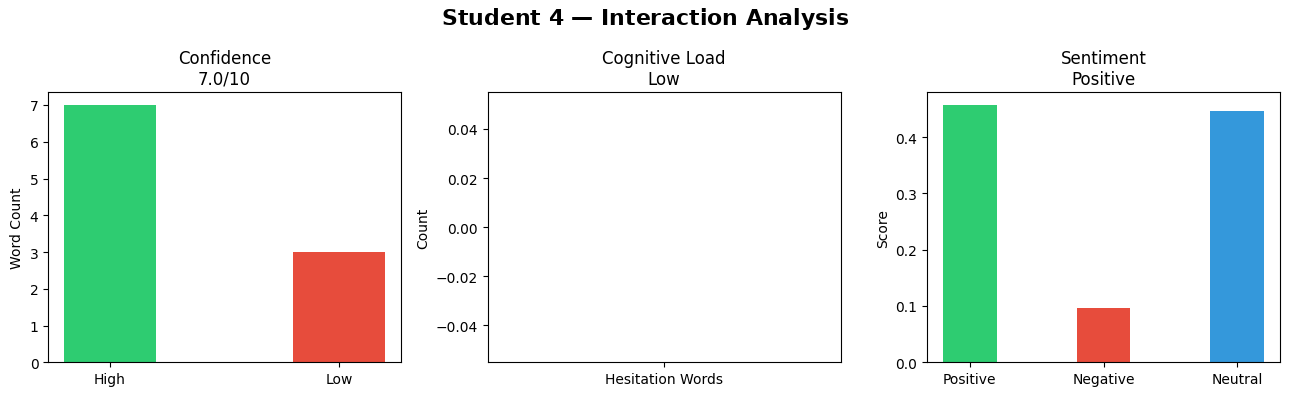

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 4
analyze_student(
    name     = "Student 4",
    session  = "FAI Mentorship Session 2",
    high_conf = ["contribute", "data science", "machine learning",
                 "coding", "excited", "yes", "will continue"],
    low_conf  = ["shyness", "weakness", "maybe", "uh",
                 "umm", "public speaking"],
    text     = """
Yes ma'am. I'm good. How are you ma'am.
Studies are fine. Yes ma'am.
Skills playing chess drawing painting coding.
Data science. Machine learning. Yes ma'am.
Public speaking shyness. Yes ma'am.
I will contribute. Yes ma'am I will continue.
Excited. Time management weakness.
Awesome. All right. Yes ma'am.
No it's terrific. Thank you.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 4.
from IPython.display import display, HTML
import re

# Searching for the specific section of Student 4 in the report_html
student4_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 4\s*</h1>.*?</div>)'
match = re.search(student4_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student4_html = match.group(1)
    display(HTML(student4_html))
else:
    print("Student 4's profiling section was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 5	.
df_final.iloc[0:1]
df_final.iloc[[4]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
4,Student 5,S-3,06/05/2026,confident,2,instant,2,mild,0,boost,2,6,Highly Engaged,S_3,06/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_3,06/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


In [ ]:
# @title 📉 Structured Analytical Gaps & Neuro Map for Student 5.

```
▶ ANALYSIS FOR: STUDENT 5
─────────────────────────────────────────────
PROFILE STATUS : Star Performance : Exceptional Potential

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


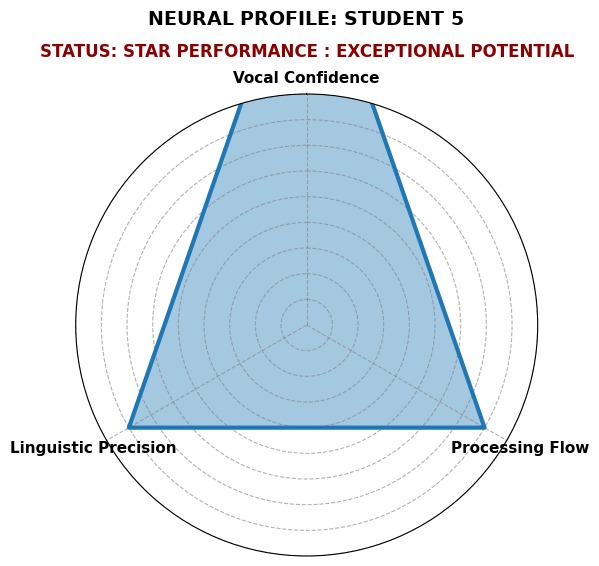

  STUDENT 5 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 3
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (0 hesitation words)
  Sentiment        : Positive (0.97)
  Positive Language: 24%
  Negative Language: 4%


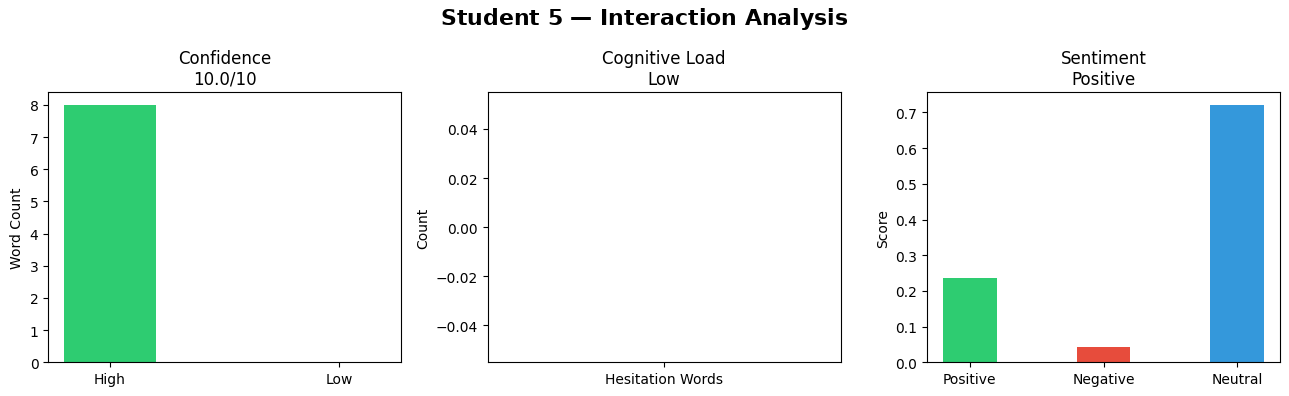

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 5.

analyze_student(
    name     = "Student 5",
    session  = "FAI Mentorship Session 3",
    high_conf = ["definitely", "interested", "AI", "data science",
                 "python", "energy", "invent", "useful", "absolutely"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "hesitant", "shy"],
    text     = """
Yes ma'am. Fine ma'am. BTech. Second semester.
Sessions are going very well. I am attending the class
and interacting sometimes with the teacher.
I am learning new things about AI. Absolutely.
I am open to various fields. I am interested in AI.
I am also interested in data science.
Videos fake photo that tempted me a lot.
If I am really into it I do it.
More energy. I am interested in it then definitely.
AutoCAD.
Ma'am both I am also be the passenger and also be
the one who invent something which will be useful for the society.
I have studied some Python in my 11th and 12th.
Yes ma'am. Everyone is patient. Doubt clear.
Thank you ma'am.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 5.
from IPython.display import display, HTML
import re

# Optimized regex to capture the full container until the start of the next profile
student5_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 5\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student5_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student5_html = match.group(1)
    display(HTML(student5_html))
else:
    # Fallback to display the header and following content if div structure is nested differently
    student5_pattern_alt = r'(<h1[^>]*>\s*Student 5\s*</h1>.*?(?=<h1|$))'
    match_alt = re.search(student5_pattern_alt, report_html, re.DOTALL | re.IGNORECASE)
    if match_alt:
        display(HTML(match_alt.group(1)))
    else:
        print("Student 5's profiling section was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 6.
df_final.iloc[0:1]
df_final.iloc[[5]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
5,Student 6,S-3,19/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S_3,06/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_3,06/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


In [ ]:
#@title 📉 Structured Analytical Gaps & Neuro Map for STUDENT 6.

```
▶ ANALYSIS FOR: STUDENT 6
─────────────────────────────────────────────
PROFILE STATUS : Star Performance : Exceptional Potential

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.



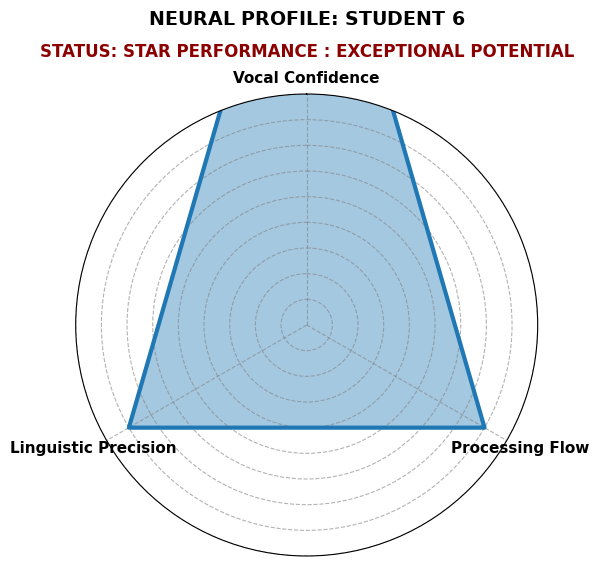

  STUDENT 6 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 3
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.98)
  Positive Language: 22%
  Negative Language: 2%


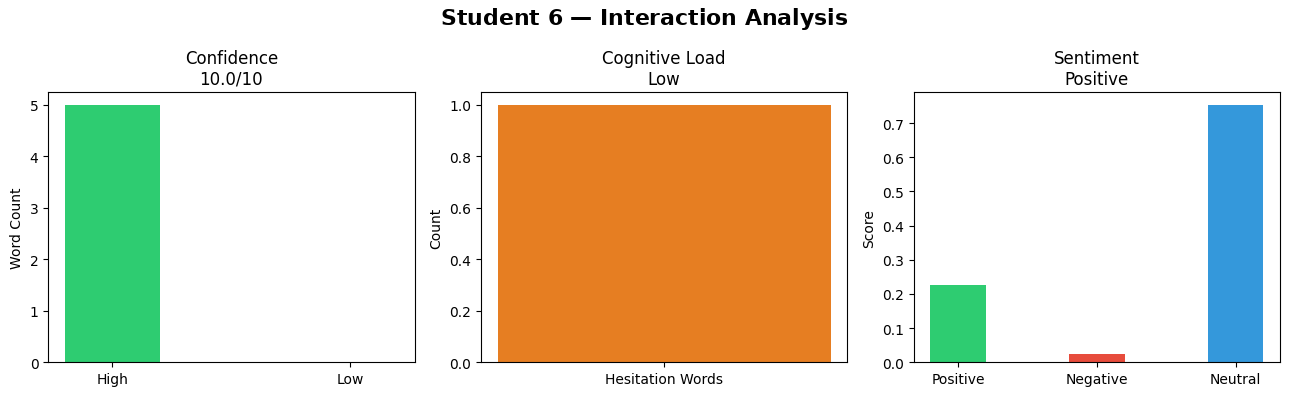

In [ ]:
#@title 🧠 Behavioral Insights from Unstructured Data for Student 6.
analyze_student(
    name     = "Student 6",
    session  = "FAI Mentorship Session 3",
    high_conf = ["definitely", "will", "contribute", "research",
                 "fascinating", "participate", "add", "helpful"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "not sure", "tough"],
    text     = """
I am doing pretty good. Alhamdulillah.
I have always been in computer field since class 11th.
I did my diploma and typing and stenography course.
Yes ma'am. Sessions are really interesting to be honest.
I really want to go into teaching profession.
AI is needed everywhere regardless of field.
Data collection thing fascinated me. AI works on data.
Everything we do goes into it and it is being used.
If you are understanding the concept it does not feel boring.
I want to know more. I want to do deep research.
Stenography and typing I am currently acquiring these skills.
I just take my time but I will not step away. I will not leave it.
If it takes more days I will take my time but I will do it.
I would like to participate not just sit and watch.
I would love to add something from my side.
Everything is really good. Discord system is really helpful.
Thank you so much.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 6.
from IPython.display import display, HTML
import re

# Searching for the specific section of Student 6 in the report_html
student6_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 6\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student6_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student6_html = match.group(1)
    display(HTML(student6_html))
else:
    # Fallback search if div structure differs
    student6_pattern_alt = r'(<h1[^>]*>\s*Student 6\s*</h1>.*?(?=<h1|$))'
    match_alt = re.search(student6_pattern_alt, report_html, re.DOTALL | re.IGNORECASE)
    if match_alt:
        display(HTML(match_alt.group(1)))
    else:
        print("Student 6's profiling section was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 7.
df_final.iloc[0:1]
df_final.iloc[[6]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
6,Student 7,S-4,08/05/2026,Anxious,-2,delayed,-2,heavy,-2,same,0,-6,Fragmented,S_4,08/05/2026,Reluctant,-2,Flat,-2,Minimally engaged,-1,Weak,-2,Delayed,-2,-1.8,Low Flow / Struggling,S_4,08/05/2026,active,2,fragmented,-2,vague,-2,-0.7,Incoherent/Struggling,Balanced Profile : Stable Baseline


📉 Structured Analytical Gaps & Neuro Map for STUDENT 7.

```
▶ ANALYSIS FOR: STUDENT 7
─────────────────────────────────────────────
PROFILE STATUS : Knowledge Gap : Targeted Training Required

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


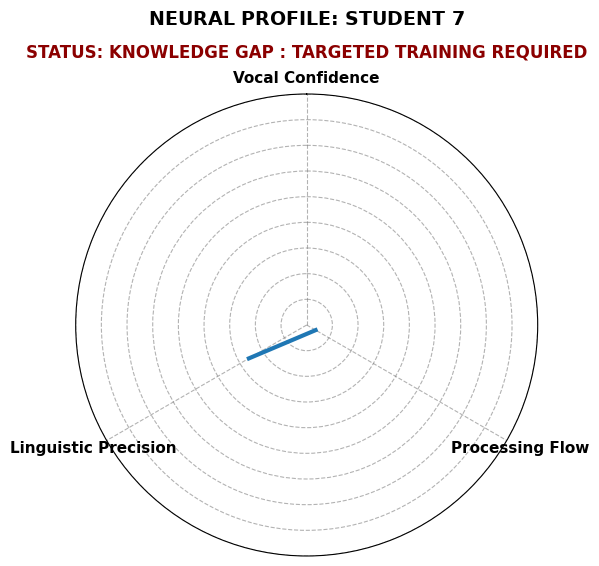

  STUDENT 7 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 4
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.55)
  Positive Language: 20%
  Negative Language: 9%


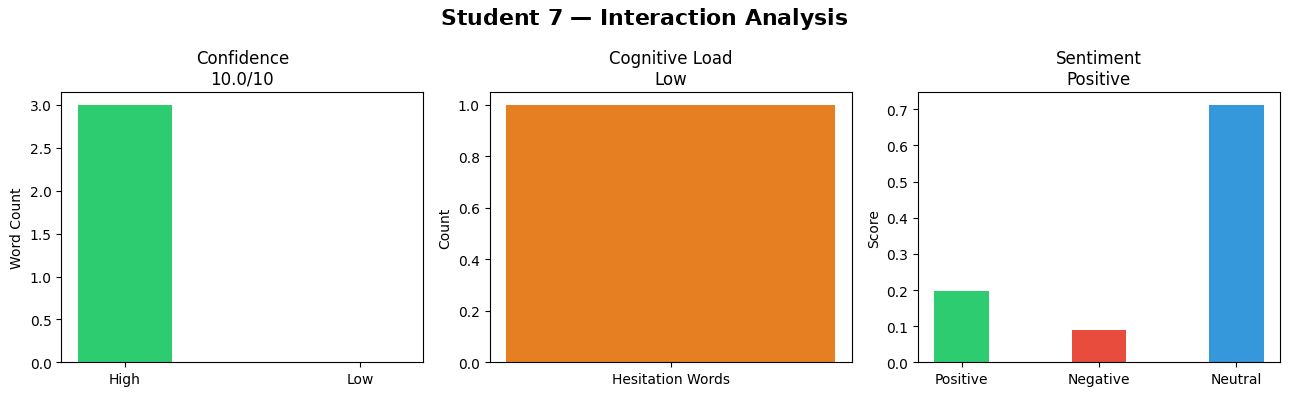

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 7.
analyze_student(
    name     = "Student 7",
    session  = "FAI Mentorship Session 4",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "data science", "energy",
                 "invent", "excited", "make", "learn"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
I'm coding website development.
G ma'am actually ma'am.
I'm excited. It excites me.
Who wants to make something?
Who wants to make something?
It encouraged me to do more to learn more.
bad and cricket.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 7.
from IPython.display import display, HTML
import re

# Extracting specifically Student 7's profile from the existing report_html variable
student7_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 7\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student7_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student7_html = match.group(1)
    display(HTML(student7_html))
else:
    print("Student 7's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 9.
df_final.iloc[0:1]
df_final.iloc[[8]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
8,Student 9,S-5,09/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S_5,09/05/2026,Responsive,0,Strongly mirror,2,Moderately engaged,0,Strong,2,Moderate,0,0.8,Steady Flow,S_5,09/05/2026,active,2,complete,2,vague,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 9.


```
▶ ANALYSIS FOR: STUDENT 9
─────────────────────────────────────────────
PROFILE STATUS : Cognitive Agile : precise thinker

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


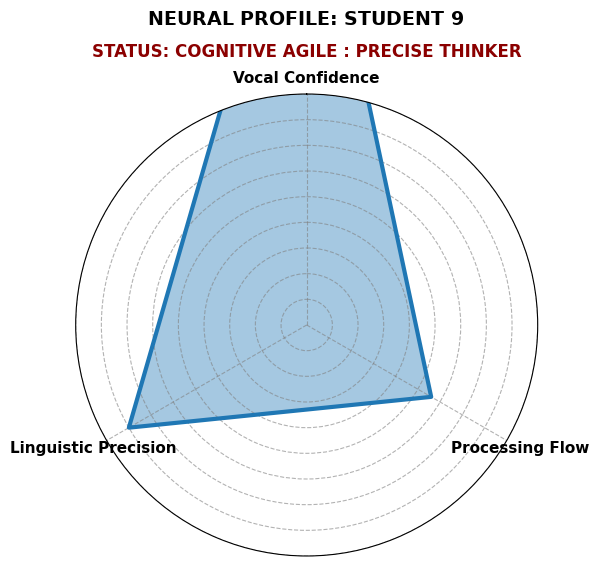

  STUDENT 9 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 5
  Analyst : Iram
  Confidence Score : 7.5/10
  Cognitive Load   : Low (2 hesitation words)
  Sentiment        : Positive (0.99)
  Positive Language: 34%
  Negative Language: 0%


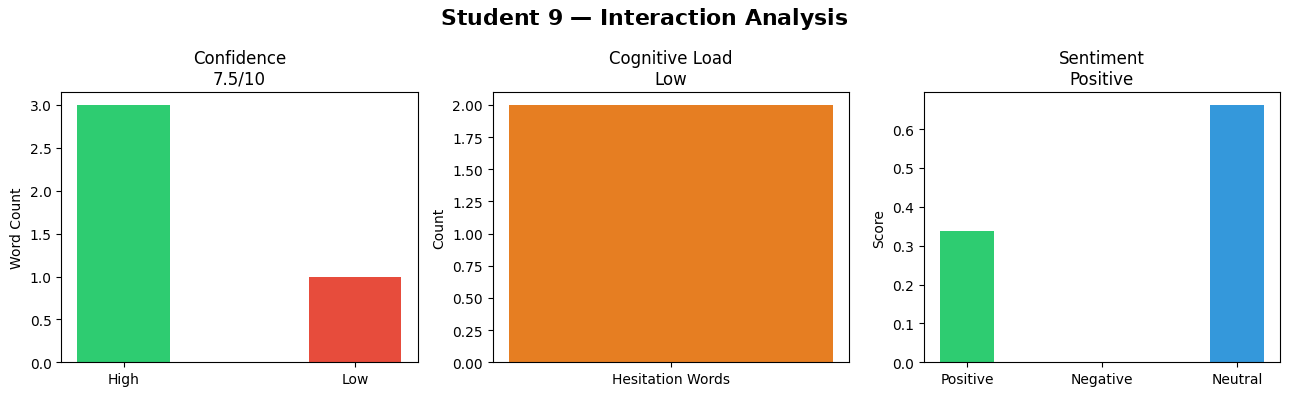

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 9.

[12]

analyze_student(
    name     = "Student 9",
    session  = "FAI Mentorship Session 5",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "energy", "invent", "make",
                 "learn", "achieve", "marketing", "best"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
Yes sir I'm fine Alhamdulillah.
I'm a science student but then change and admission
integrated masters of business administration.
Kashmir University.
guest lectures related.
Yes sir. Yes sir.
I would like to combine it with marketing.
So not in business in marketing only.
Thank you sir.
I try my best and I don't give up until I really
achieve that specific thing. Then I ask for help.
Sometimes I resist things like resistance.
assignments banana.
the second one that maybe I'll be contributing.
Yes ma'am.
Thank you so much.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 9.
from IPython.display import display, HTML
import re

# Extracting specifically Student 9's profile from the existing report_html variable
student9_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 9\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student9_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student9_html = match.group(1)
    display(HTML(student9_html))
else:
    print("Student 9's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 10.
df_final.iloc[0:1]
df_final.iloc[[9]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
9,Student 10,S-5,09/05/2026,confident,2,instant,2,mild,0,boost,2,6,Active Receptive,S_5,09/05/2026,Expressive,2,Strongly mirror,2,Moderately engaged,0,Strong,2,Moderate,0,1.2,Steady Flow,S_5,09/05/2026,active,0,complete,2,high,2,1.3,Functional/Steady,Balanced Profile : Stable Baseline



### 📉 Structured Analytical Gaps & Neuro Map for Student 10.


```
▶ ANALYSIS FOR: STUDENT 10
─────────────────────────────────────────────
PROFILE STATUS : Enthusiastic Learner : High Engagement but Needs Clarity

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


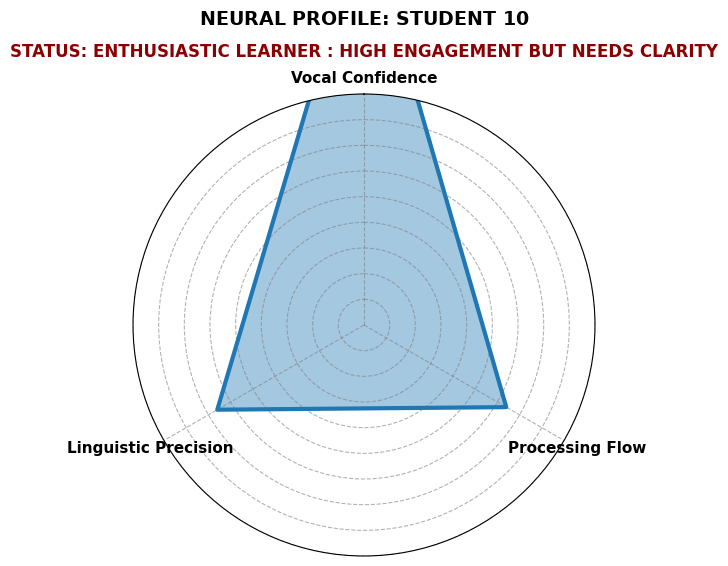

  STUDENT 10 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 5
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (0 hesitation words)
  Sentiment        : Positive (0.97)
  Positive Language: 24%
  Negative Language: 0%


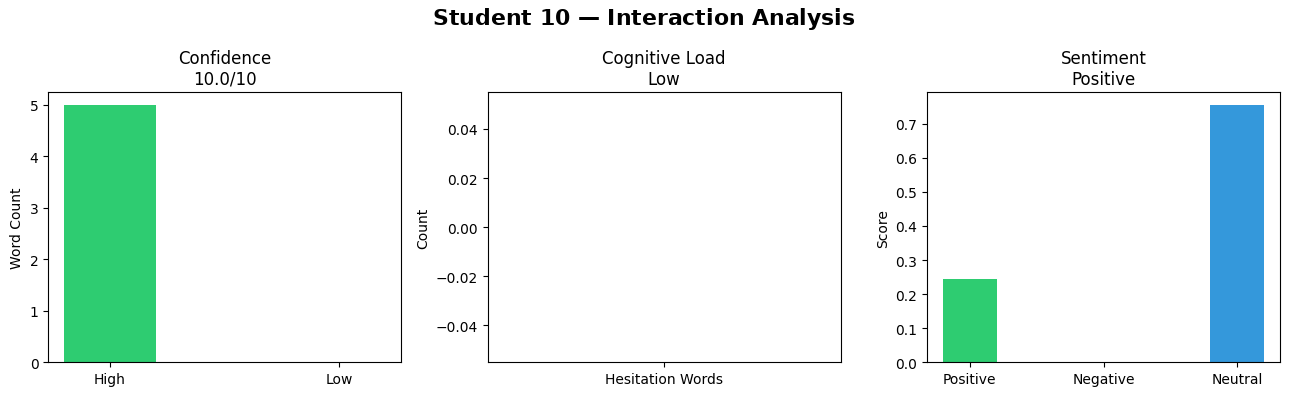

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 10.
analyze_student(
    name     = "Student 10",
    session  = "FAI Mentorship Session 5",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "energy", "invent", "make",
                 "learn", "create", "models", "train", "energetic", "Python"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
I am doing graduation in computer application from open university.
I started preparing for NET for a time.
I decided BCA as a backup.
I will love to work in future inshallah.
They are going really well foundation.
I wanted to create my own models to train them.
I am just doing Python right now.
I reach to my friends who are knowledgeable.
energetic they are making me really surprised and energetic
when I am doing some new things.
I will cope up with mathematics.
Thank you so much all of you.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 10.
from IPython.display import display, HTML
import re

# Extracting specifically Student 10's profile from the existing report_html variable
student10_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 10\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student10_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student10_html = match.group(1)
    display(HTML(student10_html))
else:
    print("Student 10's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 11.
df_final.iloc[0:1]
df_final.iloc[[10]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
10,Student 11,S_6,13/05/2026,confident,2,normal,0,mild,0,boost,2,4,Active Receptive,S_6,13/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Moderate,0,Moderate,0,0.0,Passive/Neutral,S_6,13/05/2026,passive,0,fragmented,0,vague,-2,-0.7,Incoherent/Struggling,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for STUDENT 11.

```
▶ ANALYSIS FOR: STUDENT 11
─────────────────────────────────────────────
PROFILE STATUS : Steady Contributor : Developing Profile

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


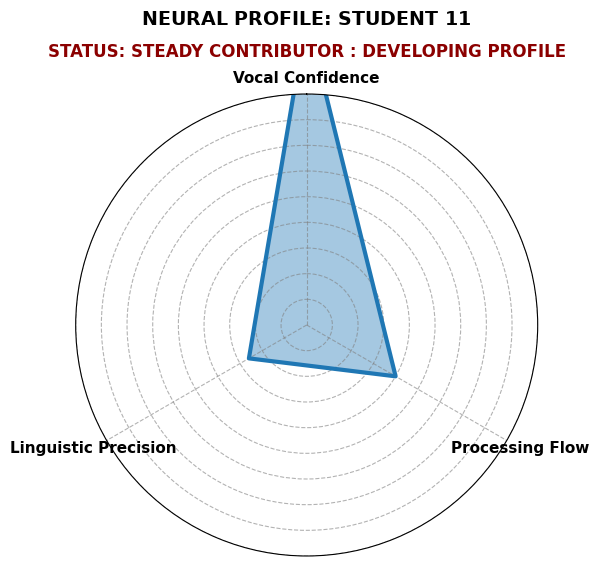

  STUDENT 11 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 6
  Analyst : Iram
  Confidence Score : 8.8/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.83)
  Positive Language: 24%
  Negative Language: 6%


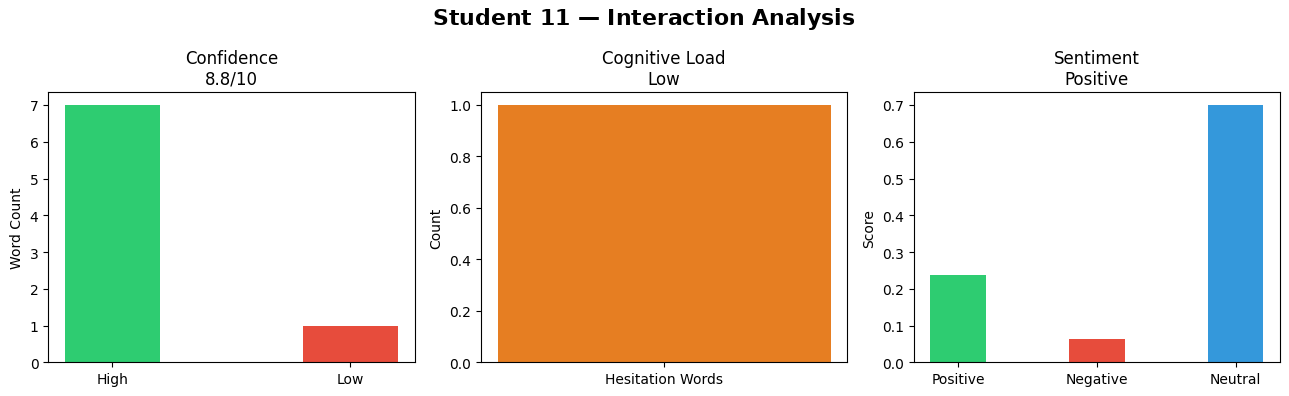

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 11.
analyze_student(
    name     = "Student 11",
    session  = "FAI Mentorship Session 6",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "energy", "invent", "make",
                 "learn", "web", "designing", "app", "technology", "continue"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
Yes ma'am.
Around 650 to 610.
Second attempt.
Our neighbor referred me.
In AI or tech background I will go for
web designing or app designing something.
Yes I will continue.
Sorry.
Thank you.
No questions as such.
Yes I want to contribute to technology.
Obviously I continue working through challenges.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 11.
from IPython.display import display, HTML
import re

# Extracting specifically Student 11's profile from the existing report_html variable
student11_dar_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 11\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student11_dar_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student11_dar_html = match.group(1)
    display(HTML(student11_dar_html))
else:
    print("Student 11's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 12.
df_final.iloc[0:1]
df_final.iloc[[11]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
11,Student 12,S_6,13/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S_6,13/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_6,13/05/2026,active,0,complete,2,high,2,1.3,Functional/Steady,Balanced Profile : Stable Baseline


### 📉 Structured Analytical Gaps & Neuro Map for STUDENT 12.

```
▶ ANALYSIS FOR: STUDENT 12
─────────────────────────────────────────────
PROFILE STATUS : Enthusiastic Learner : High Engagement but Needs Clarity

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


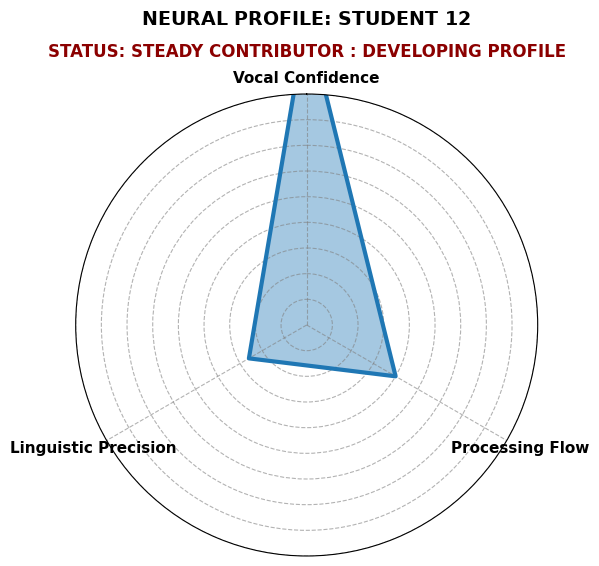

  STUDENT 12 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 6
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.99)
  Positive Language: 34%
  Negative Language: 2%


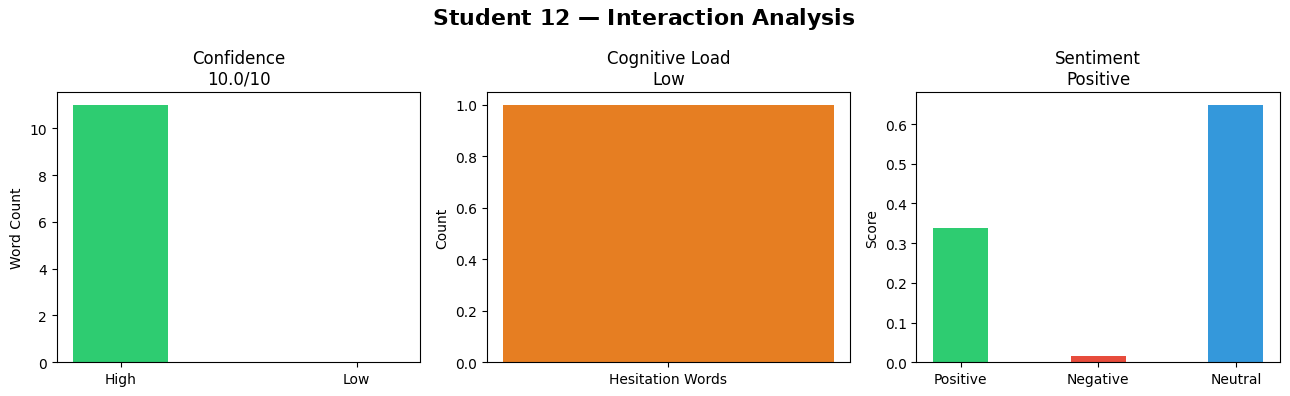

In [ ]:
#@title 🧠 Behavioral Insights from Unstructured Data for Student 12
analyze_student(
    name     = "Student 12",
    session  = "FAI Mentorship Session 6",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "energy", "invent", "make",
                 "learn", "achieve", "explore", "productive",
                 "motivate", "adapt", "grow", "prioritize"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
Pretty well. Very fine. Very interesting.
I got to know new things experiencing new things
and it is helping me really well.
It has been very interesting very helpful very productive.
I would like to combine marketing with AI.
I try my best and I don't give up until I achieve
that specific thing then I ask for help.
I always motivate myself no matter what.
I will prioritize which is more needed at a particular time.
I just want to explore new things learn new things.
I want to adapt and fit into new domains.
I just want to explore new technologies.
I will definitely give it a chance to grow professionally.
I want to contribute to new technologies.
I am that hardcore I just want to adapt everything.
Thank you so much it really means a lot.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 12.
from IPython.display import display, HTML
import re

# Extracting specifically Student 12's profile from the existing report_html variable
student12_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 12\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student12_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student12_html = match.group(1)
    display(HTML(student12_html))
else:
    print("Student 12's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 13.
df_final.iloc[0:1]
df_final.iloc[[12]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
12,Student 13,S_7,15/05/2026,confident,2,normal,0,minimal,2,same,0,4,Active Receptive,S_7,15/05/2026,Responsive,0,Partially mirror,0,Fully engaged,2,Moderate,0,Moderate,0,0.4,Passive/Neutral,S_7,15/05/2026,passive,0,complete,2,high,2,1.3,Functional/Steady,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 13.

```
▶ ANALYSIS FOR: STUDENT 13
─────────────────────────────────────────────
PROFILE STATUS : Cognitive Agile : precise thinker

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


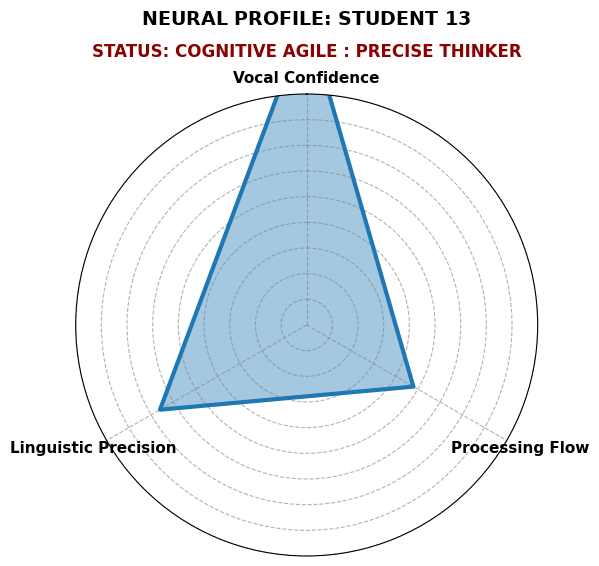

  STUDENT 13 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 7
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (2 hesitation words)
  Sentiment        : Positive (0.99)
  Positive Language: 29%
  Negative Language: 0%


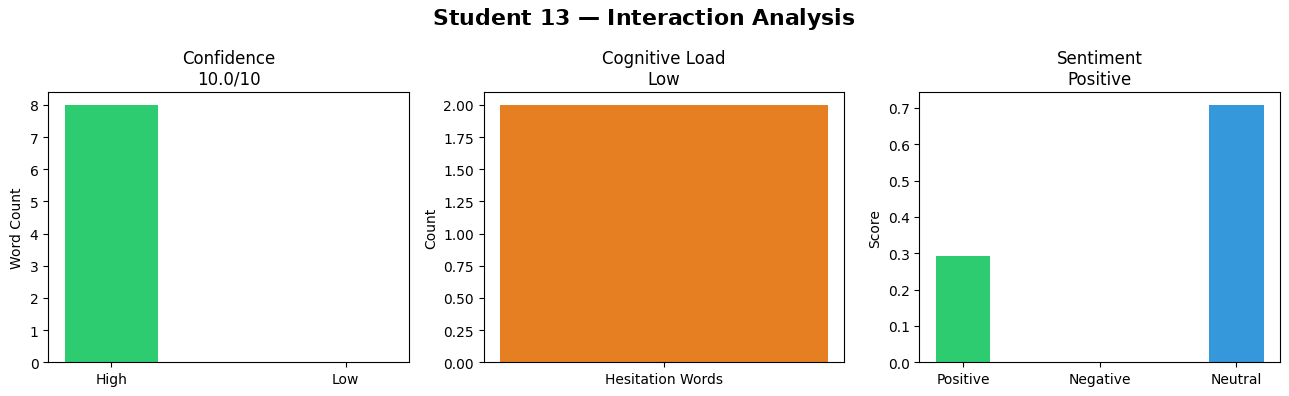

In [ ]:
#@title 🧠 Behavioral Insights from Unstructured Data for Student 13.

analyze_student(
    name     = "Student 13",
    session  = "FAI Mentorship Session 7",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "energy", "invent", "make",
                 "learn", "keen", "energetic", "best", "skills", "DAP"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
I am fine.
I am a teacher by profession private teacher.
I have done BSc and MA in public administration.
I have done BSc that was in science.
Because I wanted to join civil services.
Yes yes of course.
I wanted to add my skills.
I will try my best.
I would further go for another course of AI DAP.
Next time I will definitely try my best to interact.
I am more interested in this.
Actually I am very keen.
I feel energetic whenever I got to know anything new.
That is good for my brain.
I want to contribute in that thing.
We should definitely contribute not only use it.
I actually know already a lot of things about
Chinar quantum since you have visited our school.
Thank you thank you ma'am.
You should also take care of yourself.
"""
)

In [ ]:
#@title 🤖 Generative AI Profiling Summary for Student 13.
from IPython.display import display, HTML
import re

# Extracting specifically Student 13's profile from the existing report_html variable
student13_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 13\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student13_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student13_html = match.group(1)
    display(HTML(student13_html))
else:
    print("Student 13's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 14.
df_final.iloc[0:1]
df_final.iloc[[13]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
13,Student 14,S_7,15/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S_7,15/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S_7,15/05/2026,active,0,complete,2,high,2,1.3,Functional/Steady,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 14

```
▶ ANALYSIS FOR: STUDENT 14
─────────────────────────────────────────────
PROFILE STATUS : Enthusiastic Learner : High Engagement but Needs Clarity

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.

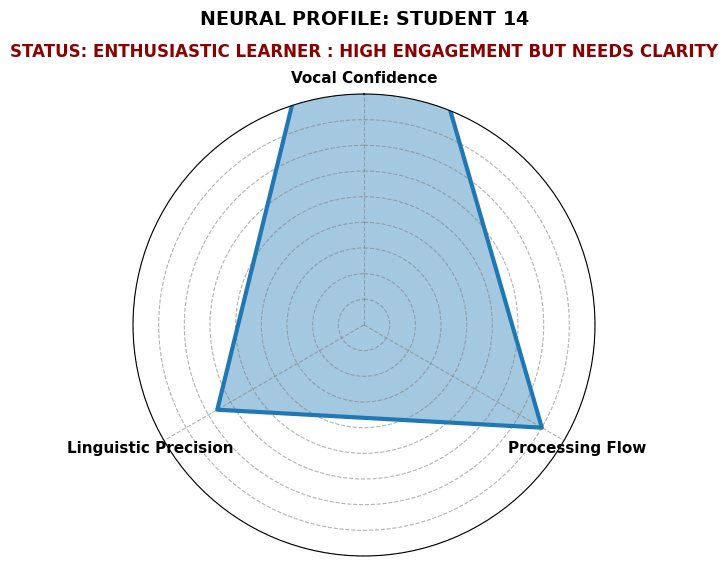

  STUDENT 14 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session 7
  Analyst : Iram
  Confidence Score : 10.0/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.98)
  Positive Language: 20%
  Negative Language: 2%


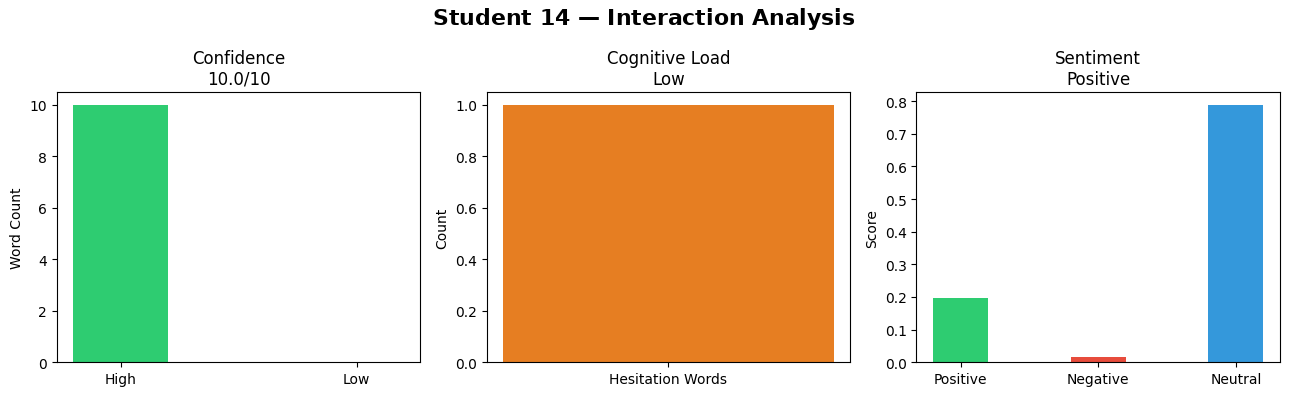

In [ ]:
#@title 🧠 Behavioral Insights from Unstructured Data for Student 14.
analyze_student(
    name     = "Student 14",
    session  = "FAI Mentorship Session 7",
    high_conf = ["definitely", "will", "contribute", "research",
                 "interested", "AI", "energy", "invent", "make",
                 "learn", "explore", "energetic", "best", "Python",
                 "data", "analytics", "achievement", "curious", "100"],
    low_conf  = ["maybe", "uh", "umm", "sorry", "shy", "weakness", "tough"],
    text     = """
I have done my graduation in computer applications.
I am pursuing my masters from IGNOU MCA.
I prefer to learn modern data science it is the future.
I know HTML CSS JavaScript and Python basic concepts.
I have interest in web development and artificial intelligence.
I am familiar with Python data libraries NumPy Pandas.
I like to explore new things whenever something comes
into trend I prefer to check how it works.
Whenever I feel difficulty I take a break for five minutes
then sit again and try to look from different angles.
Energetic definitely I feel we should learn why it is
happening and how it works.
If I get a chance to contribute to it it will be
the best achievement for me.
I will give 100 percent.
It was nice to talk to you I am really glad.
Thank you very much.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 14.
from IPython.display import display, HTML
import re

# Extracting specifically Student 14's profile from the report_html variable
# Note: Using 'Student 14' as identified in the DataFrame and previous profile generation steps
student14_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 14\s*</h1>.*?</div>)(?=\s*<div|\s*</body>|$)'
match = re.search(student14_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    student14_html = match.group(1)
    display(HTML(student14_html))
else:
    print("Student 14's profiling section was not found in the report data.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 16.
df_final.iloc[0:1]
df_final.iloc[[14]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
14,Student 16,S-8,18/05/2026,Confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S-8,18/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Moderate,0,1.6,High Flow / Leader,S-8,18/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 16.

```
▶ ANALYSIS FOR: STUDENT 16
─────────────────────────────────────────────
PROFILE STATUS : Enthusiastic Learner : High Engagement but Needs Clarity

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


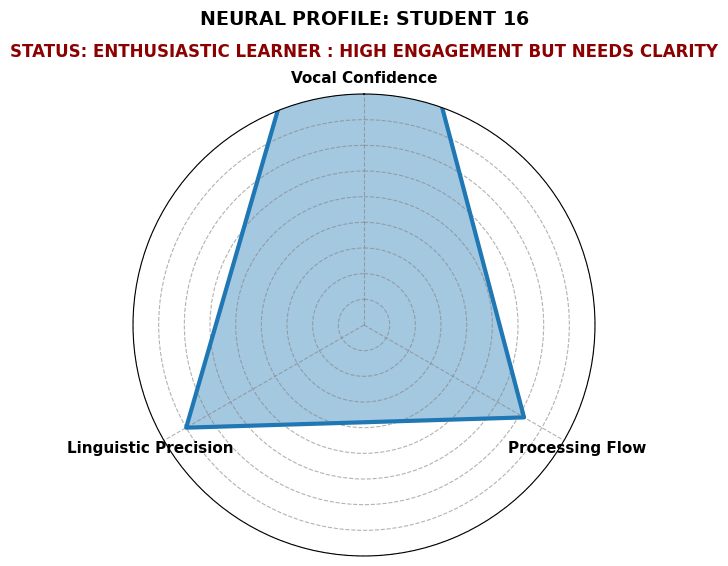

  STUDENT 16 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session
  Analyst : Iram
  Confidence Score : 7.1/10
  Cognitive Load   : Low (1 hesitation words)
  Sentiment        : Positive (0.98)
  Positive Language: 40%
  Negative Language: 4%


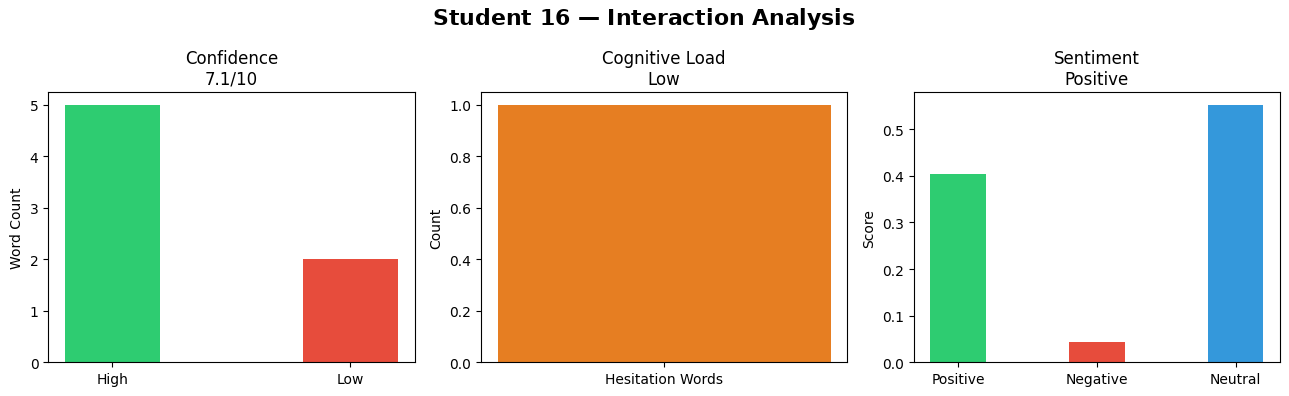

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 16.
analyze_student(
    name = "Student 16",
    session = "FAI Mentorship Session",
    high_conf = ["yes", "interesting", "contribute", "definitely", "energizes", "sure", "okay"],
    low_conf = ["sorry", "uh", "umm", "shy", "comfortable", "not sure"],
    text = """
I'm fine. How are you?
Yes ma'am.
Yes ma'am.
11th 11th CBSC school exam.
Economics, psychology, pol science, additional IP.
Green Valley.
Cousin.
It obviously energizes me.
Interesting. Yes ma'am.
Relax online. Solve.
Yes. Now.
I think I will I want to contribute. But still I want.
Camera once comfortable.
I sure give it a try.
Sorry.
Yes, ma'am. Obviously.
Thank you.
Google basics bas. Python program.
Google Python language refuse open language.
Yes, ma'am.
Thank you so much.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 16.
from IPython.display import display, HTML
import re

# Targeting 'Student 16' - capture the container and clean internal nested html/head/body tags
student16_pattern_clean = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 16\s*</h1>.*?)(?=\s*<div[^>]*>\s*<h1|\s*</body>|$)'
match = re.search(student16_pattern_clean, report_html, re.DOTALL | re.IGNORECASE)

if match:
    content = match.group(1)

    # Clean internal tags that break nested rendering
    content = re.sub(r'<!DOCTYPE.*?>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'</?(html|head|body|meta|title)[^>]*>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'<style>.*?</style>', '', content, flags=re.IGNORECASE | re.DOTALL)

    # Ensure closing div
    if content.count('<div') > content.count('</div'):
        content += '</div>'

    display(HTML(content))
else:
    print("Detailed profile data for Student 16 could not be found.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 17.
df_final.iloc[0:1]
df_final.iloc[[15]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
15,Student 17,S-8,18/05/2026,Confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S-8,18/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S-8,18/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 17.

```
▶ ANALYSIS FOR: STUDENT 17
─────────────────────────────────────────────
PROFILE STATUS : Star Performance : Exceptional Potential

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.

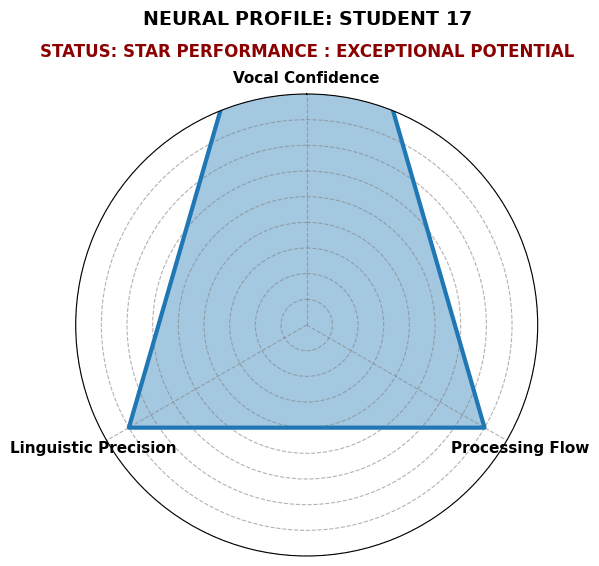

  STUDENT 17 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session
  Analyst : Iram
  Confidence Score : 6.4/10
  Cognitive Load   : Moderate (5 hesitation words)
  Sentiment        : Positive (1.0)
  Positive Language: 26%
  Negative Language: 5%


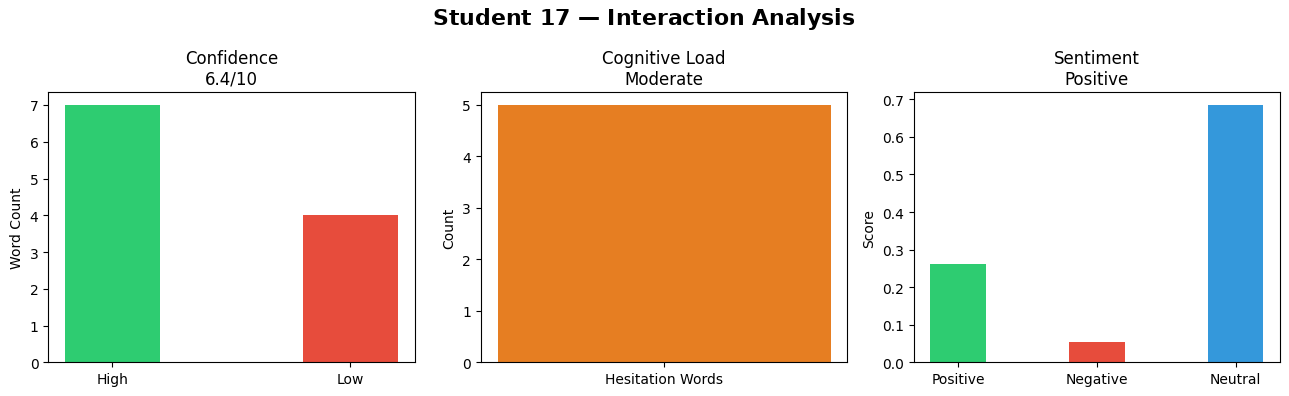

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 17.



analyze_student(
    name = "Student 17",
    session = "FAI Mentorship Session",
    high_conf = ["yes", "definitely", "contribute", "energetic", "exactly", "sure", "try"],
    low_conf = ["sorry", "uh", "umm", "shy", "introvert", "not comfortable", "not sure"],
    text = """
I'm fine. How are you doing ma'am?
Everything's good ma'am.
It's okay.
I'm in 12th and currently studying at GVI Green Valley.
Basically we two are cousins so we have opted same subject and same school like everything same.
I would say sessions interesting.
Now let's hope for the best practical instructions.
So I got to know about the CQI through Green Valley. I thought just let's give it a try.
Yes exactly.
As far as I would look for the coding but I'm not sure about time what are my future goals and aspiration but mostly it would be being a psychologist or as an economist.
Yeah exactly we can do this.
Whenever I'm exposed to new concepts my brain feels actually energetic at that time.
Definitely I would be contributing like future AI I would contribute not just use I'll try to explore new things.
AI boring task I would say basically but let me think.
So I would say again that theoretical thing, explain it in a way essay concepts. I find that difficult.
So interactive part so it's basically like shy type introvert type and talking about the camera so basically I'm not comfortable in that.
I'm trying my level best but it will take some time like introvert I am trying my best.
Yes ma'am I get it and I'm trying my best and I will try my best.
Yes ma'am I'll try.
I'll try my best.
Yes ma'am, thank you so much.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 17.

from IPython.display import display, HTML
import re

# Targeting 'Student 17' from the report_html variable
student17_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 17\s*</h1>.*?)(?=\s*<div[^>]*>\s*<h1|\s*</body>|$)'
match = re.search(student17_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    content = match.group(1)

    # Cleaning internal nested tags to ensure proper rendering in Colab
    content = re.sub(r'<!DOCTYPE.*?>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'</?(html|head|body|meta|title|style)[^>]*>', '', content, flags=re.IGNORECASE | re.DOTALL)

    # Ensure the container div is closed
    if content.count('<div') > content.count('</div'):
        content += '</div>'

    display(HTML(content))
else:
    print("AI profiling data for Student 17 was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 15.
df_final.iloc[0:1]
df_final.iloc[[16]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
16,Student 15,S-8,18/05/2026,confident,2,instant,2,mild,0,same,0,4,Active Receptive,S-8,18/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Strong,2,Moderate,0,0.4,Passive/Neutral,S-8,18/05/2026,passive,0,complete,2,vague,-2,0.0,Simple/Neutral,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 15.

```
▶ ANALYSIS FOR: STUDENT 15
─────────────────────────────────────────────
PROFILE STATUS : Steady Contributor : Developing Profile

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.


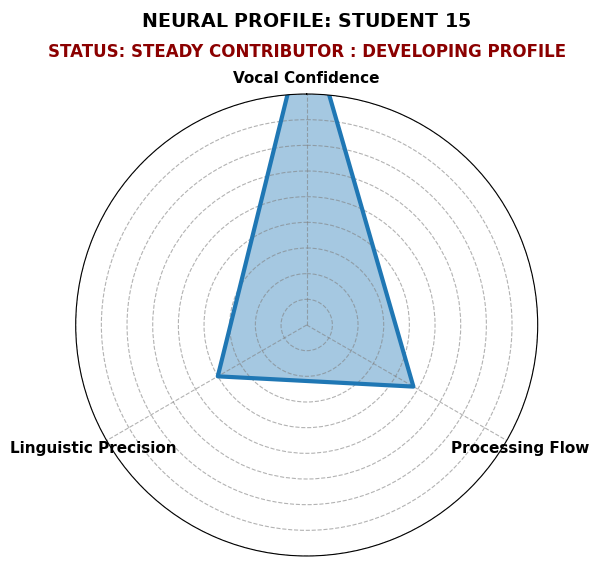

  STUDENT 15 — INTERACTION ANALYSIS
  Session : YIF Mentorship Session
  Analyst : Iram
  Confidence Score : 5.0/10
  Cognitive Load   : Low (2 hesitation words)
  Sentiment        : Positive (0.99)
  Positive Language: 19%
  Negative Language: 8%


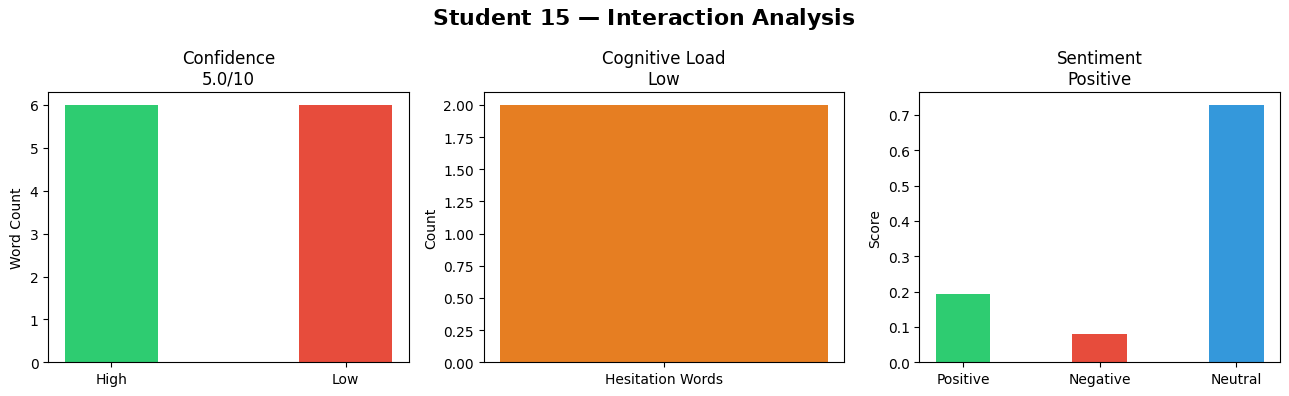

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 15.
analyze_student(
    name = "Student 15",
    session = "YIF Mentorship Session",
    high_conf = ["yes", "sure", "try my best", "good", "okay", "correct"],
    low_conf = ["sorry", "not able", "problem", "disturb", "busy", "inconvenience"],
    text = """
I'm outside currently. So I think it will be disturbing for you. So sorry for that.
Yes, I can call. Yes, I can.
As it is raining outside, so that's why I can't be able to reach home.
Sure. Sure.
It is going good but I'm not able to concentrate on that as of now because currently so much busy in my job.
My timings are fluctuating. So it's so much busy. I'm so much busy in that itself right now. Not even to concentrate on this.
I'm from Bangalore. Accountant full-time.
6:30 to 6:30.
From my side only it's having a I was having a problem. From your side according to me it's good. Nothing I don't have any problem with you all regarding sessions.
Sometimes only because of my timings I'm not able to attend a session but most of the time I'm trying my best to attend while driving also I'm keeping session on and trying to attend but that is the only problem from my side recording.
As of now I'm not seeing the recordings.
I will try my best to do what I can do from my side for attendance also for learning also. Learning perspective for everything also. I will try my best.
So sure sir. So sir, thank you very much sir.
I'm sorry for inconvenience.
No as I have attending some sessions according to me you all are explaining so good as of me so there's no doubt regarding AI everything is okay from my side.
Because as the future is going towards the AI my only hope was to learn AI, what AI can do. So many jobs are going because of AI so if we don't have any information about AI in nowadays world we cannot do anything. So my only perspective was to learn AI, what's its benefit, my only focus was that.
Don't shift. I just want to learn. I don't want to shift.
Yes. Yes. Correct.
Sure, sir. Sure.
I'll try my best.
Sure, sir. Thank you very much.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 15.
from IPython.display import display, HTML
import re

# Targeting 'Student 15' as per the dataset spelling in report_html
student15_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 15\s*</h1>.*?)(?=\s*<div[^>]*>\s*<h1|\s*</body>|$)'
match = re.search(student15_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    content = match.group(1)

    # Cleaning internal nested tags that might break rendering
    content = re.sub(r'<!DOCTYPE.*?>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'</?(html|head|body|meta|title|style)[^>]*>', '', content, flags=re.IGNORECASE | re.DOTALL)

    # Ensure the container div is properly closed
    if content.count('<div') > content.count('</div'):
        content += '</div>'

    display(HTML(content))
else:
    print("AI profiling data for Student 15 was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 18.
df_final.iloc[0:1]
df_final.iloc[[17]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
17,Student 18,S-9,19/05/2026,normal,0,normal,0,mild,0,boost,2,2,Active Receptive,S-9,19/05/2026,Responsive,0,Partially mirror,0,Moderately engaged,0,Strong,2,Moderate,0,0.4,Passive/Neutral,S-9,19/05/2026,passive,0,complete,2,vague,-2,0.0,Simple/Neutral,Balanced Profile : Stable Baseline


### 📉 Structured Analytical Gaps & Neuro Map for Student 18.

```
▶ ANALYSIS FOR: STUDENT 18
─────────────────────────────────────────────
PROFILE STATUS : Balanced Profile : Stable Baseline

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.

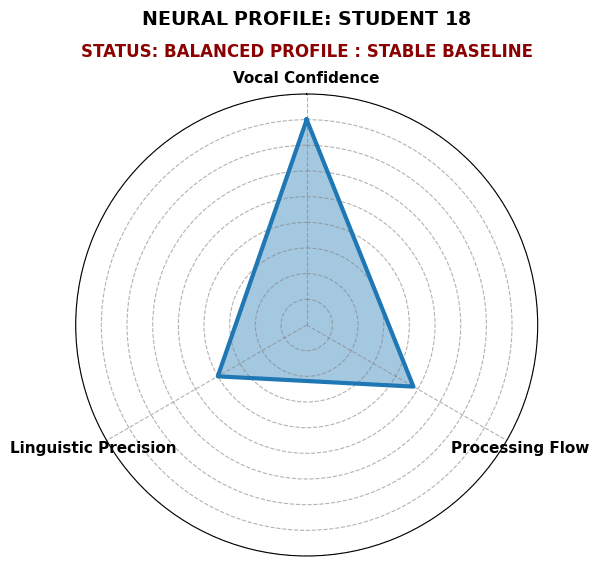

  STUDENT 18 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session
  Analyst : Iram
  Confidence Score : 6.7/10
  Cognitive Load   : Moderate (3 hesitation words)
  Sentiment        : Positive (0.97)
  Positive Language: 27%
  Negative Language: 4%


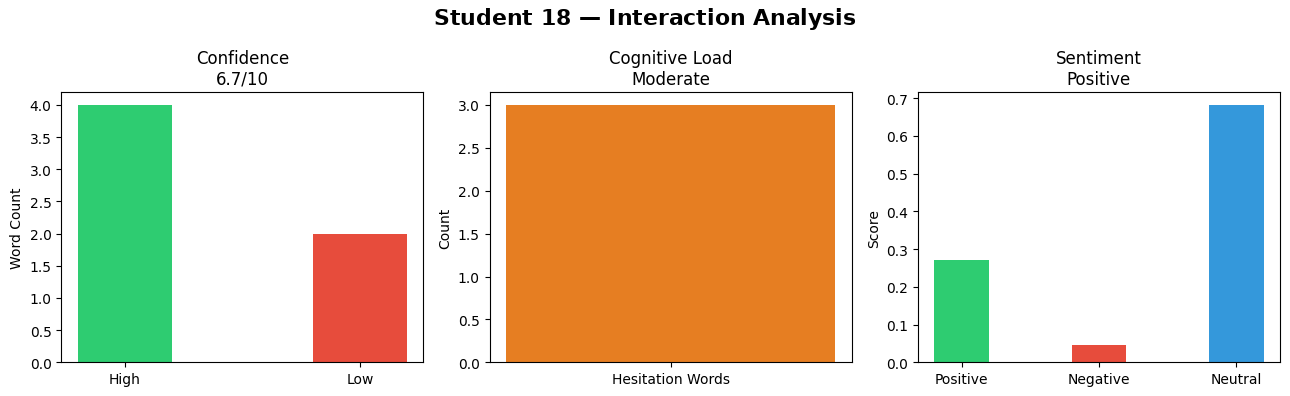

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 18.
analyze_student(
    name = "Student 18",
    session = "FAI Mentorship Session",
    high_conf = ["yes", "okay", "definitely", "energetic", "problem solver", "build career", "inshallah"],
    low_conf = ["sorry", "uh", "umm", "not sure", "disconnect", "maybe"],
    text = """
Everything is okay.
Yeah, everything is okay.
No, unofficial time, sir. Just waiting for mentorship program session.
Maybe accounting or accounting. Accounting lead license.
I want I want to do job in the field. First of all then I want to build the career and bring jobs for other persons that they can do.
I want first I want to learn that how AI works and how is beneficial to me and others.
Okay.
Everything was good.
I'm problem solver.
Basically it is feeling energetic to learn something new, something new. It's feel energetic.
I think 9 to 5 just like that.
Hology. Just like that.
Now everything is going smoothly.
The reason is uh office timing and I can't join the sessions on time. 9 to 7.
Yeah. Yeah. Because recordings.
Okay.
Inshallah.
Okay.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 18.
from IPython.display import display, HTML
import re

# Targeting 'Student 18' as per the dataset spelling in report_html
student18_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 18\s*</h1>.*?)(?=\s*<div[^>]*>\s*<h1|\s*</body>|$)'
match = re.search(student18_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    content = match.group(1)

    # Cleaning internal nested tags to ensure proper rendering in Colab
    content = re.sub(r'<!DOCTYPE.*?>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'</?(html|head|body|meta|title|style)[^>]*>', '', content, flags=re.IGNORECASE | re.DOTALL)

    # Ensure the container div is properly closed
    if content.count('<div') > content.count('</div'):
        content += '</div>'

    display(HTML(content))
else:
    print("AI profiling data for Student 18 was not found in the report.")

In [ ]:
#@title 📊 Live Observation Metrics for Student 19.
df_final.iloc[0:1]
df_final.iloc[[18]]

,Participant Name,Vocal_session ID,"Vocal_ ,b,,b vdd",Vocal_Initail Tone,Vocal_Tone Score,Vocal_Response Latency,Vocal_Latency score,Vocal_Hesitation,Vocal_hesitation score,Vocal_Energy shift,Vocal_Energy score,Vocal_Total Vocal value.,Vocal_Final lebel,Flow_session ID,Flow_Date,Flow_Participation role,Flow_Unnamed: 4,Flow_Social mirroring,Flow_Mirror Score,Flow_Engagement level,Flow_Engaegment Score,Flow_Mentor connection,Flow_Connection Score,Flow_Response Time,Flow_Response Score,Flow_Total flow value,Flow_Final lebal,Ling_session ID,Ling_Date,Ling_vocab type,Ling_vocab score,Ling_sentence structure,Ling_sentence score,Ling_clearity level,Ling_clearity score,Ling_total ling value,Ling_Final lebal,Performance_Tag
18,Student 19,S-9,19/05/2026,confident,2,instant,2,minimal,2,boost,2,8,Highly Engaged,S-9,19/05/2026,Expressive,2,Strongly mirror,2,Fully engaged,2,Strong,2,Immediate,2,2.0,High Flow / Leader,S-9,19/05/2026,active,2,complete,2,high,2,2.0,Articulate/Clear,Balanced Profile : Stable Baseline


## 📉 Structured Analytical Gaps & Neuro Map for Student 19.

```
▶ ANALYSIS FOR: STUDENT 19
─────────────────────────────────────────────
PROFILE STATUS : Star Performance : Exceptional Potential

DEEP ANALYSIS REPORT:
Consistent and reliable with a steady learning pace. They are doing well but need a push to reach their full potential.

ACADEMIC RECOMMENDATION & PATHWAY:
Standard Track: Perfectly suitable for standard Data Analytics and Python programs.



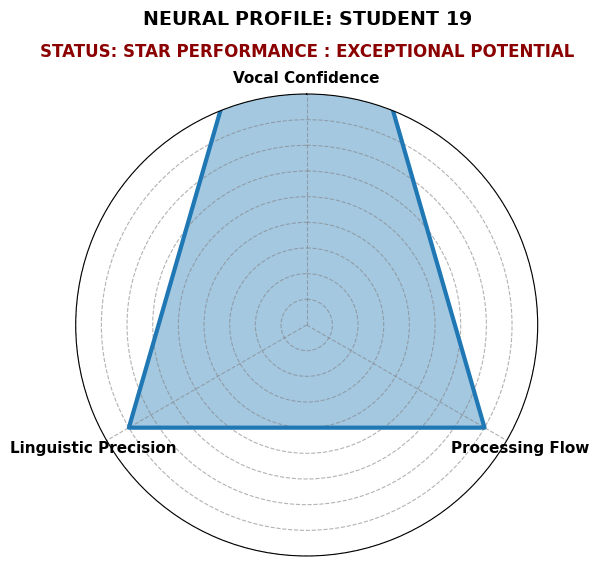

  STUDENT 19 — INTERACTION ANALYSIS
  Session : FAI Mentorship Session
  Analyst : Iram
  Confidence Score : 8.6/10
  Cognitive Load   : Low (2 hesitation words)
  Sentiment        : Positive (0.99)
  Positive Language: 29%
  Negative Language: 6%


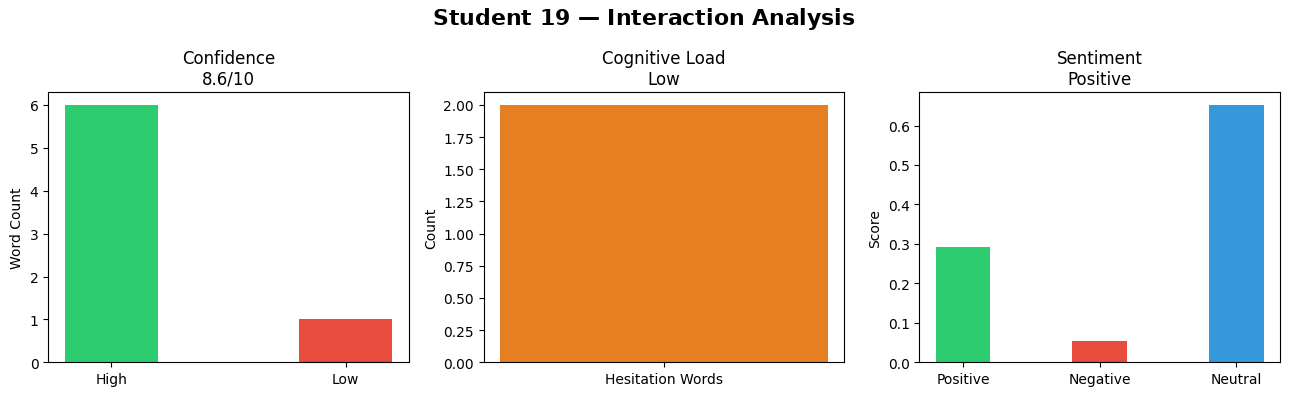

In [ ]:
# @title 🧠 Behavioral Insights from Unstructured Data for Student 19.
analyze_student(
    name = "Student 19",
    session = "FAI Mentorship Session",
    high_conf = ["yes", "definitely", "thank you", "excite", "new discovery", "contribute", "100%"],
    low_conf = ["sorry", "uh", "umm", "difficult", "not sure", "problem"],
    text = """
Because of drug discovery, it's widely used to design, discover, development new drugs faster, help in finding new drugs, molecules, predicting chemicals may work against disease, reducing time and cost of clinical research. Also identify side effects.
Yes, there is sir. Pharmacology.
I'm happy for this sir. Thank you sir. It's a great sir.
Yes sir.
Yes, sir.
Definitely definitely. Is it.
No, no sir. Guess it actually.
Difficult number actually number is not measure. First sir 100% sir. This phone number is unable to be asserted with account.
Okay, hold this.
No, no ma'am. Complete timeline.
Discovery. Excite. Next coffee is.
Drug effects people toxic. Amen. I think yes.
Yes ma'am. I want to do new projects regarding the new discovery of drugs. Venopro example is new new discovery of new drugs, new patents.
Yes. Yes.
Regarding drugs, regarding healthcare. Yes. Medical college. Treatment.
Yeah. Ma'am, PPI, Protonator. Easily misuse almost 50% was getting a body when you using chemotherapy.
Thank you. Thank you, ma'am.
"""
)

In [ ]:
# @title 🤖 Generative AI Profiling Summary for Student 19.
from IPython.display import display, HTML
import re

# Targeting 'Student 19' and aggressively cleaning metadata/style artifacts
student19_pattern = r'(<div[^>]*>\s*<h1[^>]*>\s*Student 19\s*</h1>.*?)(?=\s*<div[^>]*>\s*<h1|\s*</body>|$)'
match = re.search(student19_pattern, report_html, re.DOTALL | re.IGNORECASE)

if match:
    content = match.group(1)

    # Remove internal style, title, meta, and head tags entirely to remove 'numbers and text' artifacts
    content = re.sub(r'<style.*?>.*?</style>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'<title.*?>.*?</title>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'<!DOCTYPE.*?>', '', content, flags=re.IGNORECASE | re.DOTALL)
    content = re.sub(r'</?(html|head|body|meta|link)[^>]*>', '', content, flags=re.IGNORECASE | re.DOTALL)

    # Cleaning common LLM artifacts sometimes left behind
    content = content.replace('\t', ' ').replace('\n', ' ')

    # Ensure the container div is properly closed
    if content.count('<div') > content.count('</div'):
        content += '</div>'

    display(HTML(content))
else:
    print("AI profiling data for Student 19 was not found in the report.")

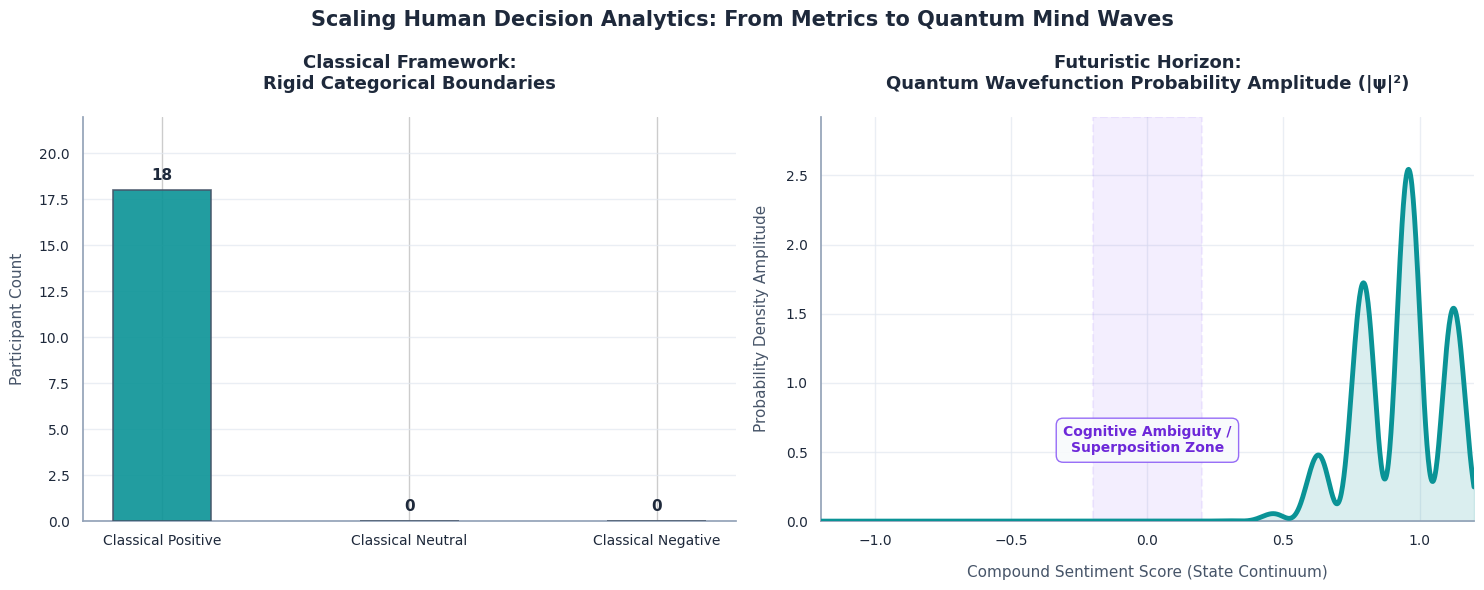

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Authentic 18-participant sentiment score (S.S) dataset array
collective_scores = np.array([
    0.98, 0.97, 0.97, 0.98, 0.97, 0.98, 0.55, 0.99, 0.97,
    0.83, 0.99, 0.99, 0.98, 0.98, 1.00, 0.99, 0.97, 0.99
])

# 2. Configure a widescreen presentation layout (15x6 inches)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.0))
sns.set_theme(style="whitegrid")

# Premium scientific white background setup
fig.patch.set_facecolor('#FFFFFF')
ax1.set_facecolor('#FFFFFF')
ax2.set_facecolor('#FFFFFF')

# PANEL 1 (LEFT): CLASSICAL METRIC BOUNDARIES (Empirical Counts: 18, 0, 0)
pos_count = int(np.sum(collective_scores > 0.05))
neu_count = int(np.sum((collective_scores >= -0.05) & (collective_scores <= 0.05)))
neg_count = int(np.sum(collective_scores < -0.05))

categories = ['Classical Positive', 'Classical Neutral', 'Classical Negative']
counts = [pos_count, neu_count, neg_count]
bar_colors = ['#0A9396', '#94A3B8', '#E63946']

bars = ax1.bar(categories, counts, color=bar_colors, width=0.4, alpha=0.9,
               edgecolor='#475569', linewidth=1.2, zorder=3)
ax1.set_title('Classical Framework:\nRigid Categorical Boundaries', fontsize=13, color='#1E293B', weight='bold', pad=20)
ax1.set_ylabel('Participant Count', fontsize=11, color='#475569', labelpad=10)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, str(yval),
             ha='center', va='bottom', color='#1E293B', weight='bold', fontsize=11)

ax1.set_ylim(0, 22)
ax1.tick_params(colors='#1E293B', labelsize=10)
ax1.grid(True, color='#E2E8F0', linestyle='-', alpha=0.7, axis='y', zorder=0)
ax1.spines['bottom'].set_color('#94A3B8')
ax1.spines['left'].set_color('#94A3B8')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# PANEL 2 (RIGHT): TRUE QUANTUM COGNITION WAVE FUNCTION (Continuous Amplitude Matrix)
x_axis = np.linspace(-1.2, 1.2, 1000)
mean_val = np.mean(collective_scores)
std_val = 0.18
base_envelope = (1 / (std_val * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_axis - mean_val) / std_val)**2)

# Quantum interference simulation engine mapping 18 participant nodes
interference_frequency = 18.0
wave_modulation = (np.sin(interference_frequency * x_axis) ** 2) + 0.15
quantum_wavefunction = base_envelope * wave_modulation

ax2.plot(x_axis, quantum_wavefunction, color='#0A9396', linewidth=3.5, zorder=3)
ax2.fill_between(x_axis, 0, quantum_wavefunction, color='#0A9396', alpha=0.15, zorder=2)

# Shading the Cognitive Superposition Zone (-0.2 to +0.2)
ax2.axvspan(-0.2, 0.2, color='#8B5CF6', alpha=0.1, linestyle='--', linewidth=1.5, zorder=1)

ax2.set_title('Futuristic Horizon:\nQuantum Wavefunction Probability Amplitude (|ψ|²)', fontsize=13, color='#1E293B', weight='bold', pad=20)
ax2.set_xlabel('Compound Sentiment Score (State Continuum)', fontsize=11, color='#475569', labelpad=12)
ax2.set_ylabel('Probability Density Amplitude', fontsize=11, color='#475569', labelpad=12)

ax2.set_xlim(-1.2, 1.2)
ax2.set_ylim(0, np.max(quantum_wavefunction) * 1.15)
ax2.tick_params(colors='#1E293B', labelsize=10)
ax2.grid(True, color='#E2E8F0', linestyle='-', alpha=0.7, zorder=0)
ax2.spines['bottom'].set_color('#94A3B8')
ax2.spines['left'].set_color('#94A3B8')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# FIX: Extract upper boundary index [1] from get_ylim() before scaling
ax2.text(0.0, ax2.get_ylim()[1]*0.2, 'Cognitive Ambiguity /\nSuperposition Zone', color='#6D28D9',
         fontsize=10, weight='bold', ha='center', va='center',
         bbox=dict(facecolor='#F8FAFC', alpha=0.9, edgecolor='#8B5CF6', boxstyle='round,pad=0.5', linewidth=1))

plt.suptitle('Scaling Human Decision Analytics: From Metrics to Quantum Mind Waves',
             fontsize=15, color='#1E293B', weight='bold', y=0.98)
plt.tight_layout()
plt.show()